# Which customers should we try to keep?

A phone and internet company cannot call, or give a discount to, every customer who might leave. Staff time and offer money are limited. If the company can only contact **10%** of current customers, who should those people be, so that as much monthly revenue as possible is protected?

Each customer is scored by

$$
\text{revenue at risk} = \hat{p}(\text{leave}) \times \text{monthly charges}
$$

The top 10% form the call list. The same number of slots is also given to four simple rules a manager could run without a model (newest first, contract leave-rate × bill, a five-flag risk count × bill, and largest bills). Four scoring methods compete: logistic regression, a random forest, XGBoost, and a small neural network. A more complex method replaces logistic regression only if it covers at least **2 extra percentage points** of lost monthly bills on the training folds.

The file is `WA_Fn-UseC_-Telco-Customer-Churn.csv`: 7,043 customers, one row per customer, on a single extract date. `Churn` records that the customer had already left. There is no leave date and no record of past keep-offers.

Two things beyond the original version of this notebook: model differences are reported with uncertainty (repeated cross-validation on the training folds and a bootstrap on the test group), and the manager-rule benchmark now includes a multi-flag rule that is much closer to what a model-free analyst would build.


## 1. Setup


In [1]:
%matplotlib inline

from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 3803
BUDGET = 0.10
BUDGETS = [0.05, 0.10, 0.15, 0.20, 0.30]
MODEL_MARGIN = 0.02
CONTRACT_ORDER = ["Month-to-month", "One year", "Two year"]
ADDONS = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]
CATEGORICAL = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]
FEATURE_COLUMNS = ["tenure", "MonthlyCharges", "SeniorCitizen", *CATEGORICAL]

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})


def find_data():
    candidates = [
        Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
        Path("archive") / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError("Telco churn CSV not found in the project directory.")


def percent(frame, columns):
    view = frame.copy()
    for column in columns:
        view[column] = view[column].map(
            lambda value: "" if pd.isna(value) else f"{value:.1%}"
        )
    return view


def money(frame, columns):
    view = frame.copy()
    for column in columns:
        view[column] = view[column].map(lambda value: f"${value:,.2f}")
    return view


def capture_share(y_true, bill, score, fraction):
    y_true = np.asarray(y_true)
    bill = np.asarray(bill, dtype=float)
    chosen = np.argsort(-np.asarray(score, dtype=float), kind="mergesort")
    k = max(1, int(round(len(y_true) * fraction)))
    chosen = chosen[:k]
    churned_revenue = bill[y_true == 1].sum()
    covered = bill[chosen][y_true[chosen] == 1].sum()
    return covered / churned_revenue


def top_positions(score, k):
    return set(np.argsort(-np.asarray(score, dtype=float), kind="mergesort")[:k])


def contract_tenure_score(contract, tenure):
    rank = pd.Series(contract).map({"Month-to-month": 2, "One year": 1, "Two year": 0})
    return rank.to_numpy(dtype=float) * 1000 - np.asarray(tenure, dtype=float)


def flag_count(frame):
    """Manager rule: one point for each of five risk flags seen in the explore tables."""
    return (
        (frame["Contract"] == "Month-to-month").astype(int)
        + (frame["InternetService"] == "Fiber optic").astype(int)
        + (frame["OnlineSecurity"] == "No").astype(int)
        + (frame["TechSupport"] == "No").astype(int)
        + (frame["PaymentMethod"] == "Electronic check").astype(int)
    ).to_numpy(dtype=float)


def make_pipeline(estimator):
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), ["tenure", "MonthlyCharges"]),
            ("senior", "passthrough", ["SeniorCitizen"]),
            (
                "categorical",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                CATEGORICAL,
            ),
        ]
    )
    return Pipeline([("preprocess", preprocessor), ("model", estimator)])


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load and explore

One row is one customer. The outcome is whether they had already left (`Churn`). The 10% contact limit is tight enough to force a ranking inside the month-to-month group, which is already 55% of the list.


**Read the target with care.** `Churn` marks customers who had already left by the extract date, and `tenure` is months to that date: frozen at departure for leavers, still running for stayers. Short tenure therefore partly means "left early", which a live customer base cannot show in the same way. The scores below rank who *looks like* past leavers. They are not a forecast of who leaves next month.

In [2]:
DATA_PATH = find_data()
raw = pd.read_csv(DATA_PATH)
raw["churn"] = (raw["Churn"] == "Yes").astype(int)
raw["TotalCharges_num"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")

print(f"File: {DATA_PATH}")
print(f"Customers: {len(raw):,}")
print(f"Leavers: {int(raw['churn'].sum()):,} ({raw['churn'].mean():.1%})")
print(f"Blank TotalCharges: {int(raw['TotalCharges_num'].isna().sum())}")
print(f"Tenure 0: {int((raw['tenure'] == 0).sum())}")
display(raw.drop(columns=["churn", "TotalCharges_num"]).head())


def group_rates(frame, column):
    rows = []
    lost = frame.loc[frame["churn"] == 1, "MonthlyCharges"].sum()
    for label, part in frame.groupby(column, observed=True):
        left = part[part["churn"] == 1]
        rows.append({
            column: label,
            "customers": int(len(part)),
            "share_of_customers": len(part) / len(frame),
            "share_who_left": part["churn"].mean(),
            "mean_bill": part["MonthlyCharges"].mean(),
            "share_of_lost_bills": left["MonthlyCharges"].sum() / lost,
        })
    table = pd.DataFrame(rows)
    if column == "Contract":
        table[column] = pd.Categorical(table[column], CONTRACT_ORDER, ordered=True)
        table = table.sort_values(column)
    else:
        table = table.sort_values("share_who_left", ascending=False)
    return table


rate_columns = ["share_of_customers", "share_who_left", "share_of_lost_bills"]
print("Contract")
display(money(percent(group_rates(raw, "Contract"), rate_columns), ["mean_bill"]))
print("Internet service")
display(money(percent(group_rates(raw, "InternetService"), rate_columns), ["mean_bill"]))
print("Payment method")
display(money(percent(group_rates(raw, "PaymentMethod"), rate_columns), ["mean_bill"]))
print("Online security")
display(money(percent(group_rates(raw, "OnlineSecurity"), rate_columns), ["mean_bill"]))


File: WA_Fn-UseC_-Telco-Customer-Churn.csv
Customers: 7,043
Leavers: 1,869 (26.5%)
Blank TotalCharges: 11
Tenure 0: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Contract


,Contract,customers,share_of_customers,share_who_left,mean_bill,share_of_lost_bills
0,Month-to-month,3875,55.0%,42.7%,$66.40,86.9%
1,One year,1473,20.9%,11.3%,$65.05,10.1%
2,Two year,1695,24.1%,2.8%,$60.77,3.0%


Internet service


,InternetService,customers,share_of_customers,share_who_left,mean_bill,share_of_lost_bills
1,Fiber optic,3096,44.0%,41.9%,$91.50,82.2%
0,DSL,2421,34.4%,19.0%,$58.10,16.2%
2,No,1526,21.7%,7.4%,$21.08,1.7%


Payment method


,PaymentMethod,customers,share_of_customers,share_who_left,mean_bill,share_of_lost_bills
2,Electronic check,2365,33.6%,45.3%,$76.26,60.6%
3,Mailed check,1612,22.9%,19.1%,$43.92,12.1%
0,Bank transfer (automatic),1544,21.9%,16.7%,$67.19,14.4%
1,Credit card (automatic),1522,21.6%,15.2%,$66.51,12.9%


Online security


,OnlineSecurity,customers,share_of_customers,share_who_left,mean_bill,share_of_lost_bills
0,No,3498,49.7%,41.8%,$75.69,81.0%
2,Yes,2019,28.7%,14.6%,$78.84,17.3%
1,No internet service,1526,21.7%,7.4%,$21.08,1.7%


Month-to-month customers are 55% of the list and 86.9% of the monthly bills that were lost. About 43 in 100 of them had left, against 11 in 100 on a one-year contract and 3 in 100 on a two-year contract. Fibre customers leave more often and pay more. Paying by electronic check and having no online security also mark higher leave rates.

The file is a teaching sample. It has no complaints, outages, rival offers, sign-up date, or leave date. Eleven customers have tenure 0 and a blank total billed amount. They are new accounts and stay in the file so a new customer can still be scored.


## 3. Prepare

`customerID` is dropped. `TotalCharges` is dropped because it almost exactly repeats tenure times the current monthly bill. The next section checks whether the leftover gap, or a tenure × contract term, should be added back. Optional extras are recoded to Yes or No so "no internet" is not copied into six columns. Internet type and phone service stay as their own fields.

The split is 80/20, stratified on leaving, seed 3803, and it is made before any model is fit. Because there are no dates, the test group is another slice of the same day, not later customers. Hyperparameters and the choice of model use five folds **inside the training sample**. The 1,409 test customers are scored once, after that choice.

Class weights stay at the default. The call score multiplies the predicted chance of leaving by the bill, so that chance needs to mean what it says. Section 7 checks calibration on the test group rather than assuming it.


In [3]:
billed = raw["TotalCharges_num"].notna()
tenure_times_bill = raw["tenure"] * raw["MonthlyCharges"]
print(
    "Correlation of TotalCharges with tenure x monthly charges: "
    f"{raw.loc[billed, 'TotalCharges_num'].corr(tenure_times_bill[billed]):.4f}"
)

X = raw.drop(columns=["customerID", "Churn", "churn", "TotalCharges", "TotalCharges_num"]).copy()
for column in ADDONS:
    X[column] = np.where(X[column] == "Yes", "Yes", "No")
X["MultipleLines"] = np.where(X["MultipleLines"] == "Yes", "Yes", "No")
X = X[FEATURE_COLUMNS]
y = raw["churn"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y,
)
print(f"Training customers: {len(X_train):,}")
print(f"Test customers: {len(X_test):,}")
print(f"Training leave rate: {y_train.mean():.1%}")
print(f"Test leave rate: {y_test.mean():.1%}")


Correlation of TotalCharges with tenure x monthly charges: 0.9996
Training customers: 5,634
Test customers: 1,409
Training leave rate: 26.5%
Test leave rate: 26.5%


## 4. Feature engineering we considered

Two extra fields are natural to try first, followed by six further candidates. None is added to the four scoring models unless it improves 10% lost-bill coverage on the training folds.

**Price change.** The current monthly bill minus `TotalCharges / tenure`. If this file contained a real price history, a large positive gap would mean the customer is now paying more than they used to (an upgrade, a lapsed discount, or a price rise). The 11 new accounts have no history; their gap is set to $0.

**Tenure × month-to-month.** Logistic regression currently gives time with the company one slope for every contract type. Leave rates fall with tenure among month-to-month customers and are almost flat on one-year and two-year contracts, so a product term is the obvious interaction.

The decision uses only the training folds and the same 10% coverage number as the rest of the notebook. The test group is not used here. The extra columns are not written into `FEATURE_COLUMNS`.

Training customers with a billing history: 5,625
Mean price change: $0.01
Typical absolute gap: $1.74
Share within $5: 93.8%
Correlation of current bill with TotalCharges / tenure: 0.996
Correlation of price change with leaving: 0.004


,gap,customers,share_who_left,mean_bill,mean_tenure
0,Current bill >$1 below history,1545,26.9%,$70.23,31.187702
1,About the same,2552,25.7%,$58.11,34.557210
2,Current bill >$1 above history,1537,27.5%,$70.36,30.602472


Share who left, training customers


Contract,tenure_band,Month-to-month,One year,Two year
0,0-6 mo,55.4%,8.6%,0.0%
1,7-12,40.8%,9.4%,0.0%
2,13-24,39.0%,8.6%,0.0%
3,25-48,33.8%,10.3%,2.6%
4,49-72,25.5%,13.8%,3.0%


Customer counts


Contract,tenure_band,Month-to-month,One year,Two year
0,0-6 mo,1126,35,21
1,7-12,468,64,28
2,13-24,580,152,76
3,25-48,627,418,228
4,49-72,274,508,1029


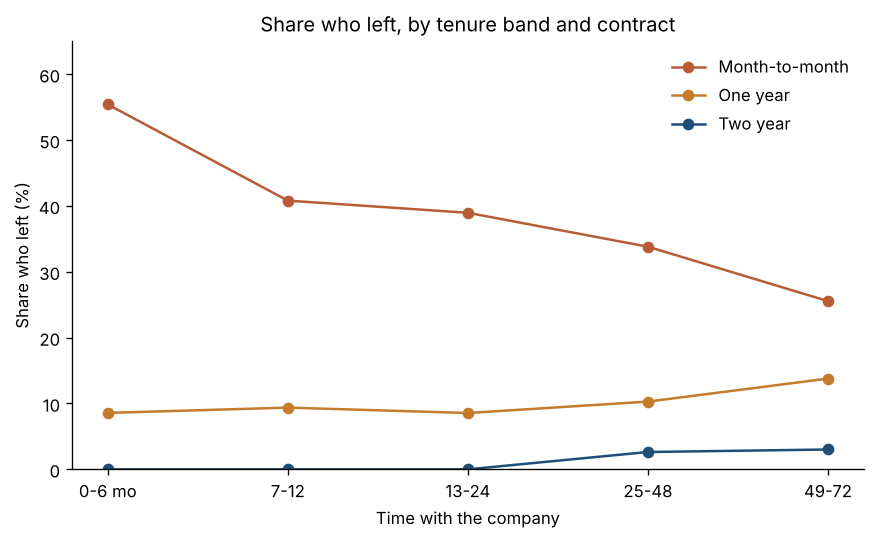

,specification,cv_coverage,cv_std,cv_roc_auc,cv_minus_baseline
0,Baseline logistic,33.4%,0.9%,84.5%,0.00 pp
1,Plus price change,33.7%,0.8%,84.4%,+0.26 pp
2,Plus tenure x month-to-month,33.4%,0.9%,84.7%,-0.01 pp
3,Plus both,33.7%,0.8%,84.6%,+0.24 pp


Training folds only: the test group is not touched in this section.
These columns are not added to FEATURE_COLUMNS. The four scoring models below use the prepared fields only.


In [4]:
def attach_candidates(frame):
    out = frame.copy()
    total = raw.loc[frame.index, "TotalCharges_num"].to_numpy(dtype=float)
    tenure = frame["tenure"].to_numpy(dtype=float)
    monthly = frame["MonthlyCharges"].to_numpy(dtype=float)
    avg_hist = np.where(tenure > 0, total / tenure, np.nan)
    out["price_change"] = np.nan_to_num(monthly - avg_hist, nan=0.0)
    out["tenure_x_m2m"] = tenure * (frame["Contract"] == "Month-to-month").to_numpy(dtype=float)
    return out


def extra_pipeline(numeric_extra):
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), ["tenure", "MonthlyCharges", *numeric_extra]),
            ("senior", "passthrough", ["SeniorCitizen"]),
            (
                "categorical",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                CATEGORICAL,
            ),
        ]
    )
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000, solver="lbfgs", C=2.0)),
    ])


def extra_cv_coverage(frame, target, numeric_extra):
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    shares, aucs = [], []
    pipe_template = extra_pipeline(numeric_extra)
    cols = ["tenure", "MonthlyCharges", *numeric_extra, "SeniorCitizen", *CATEGORICAL]
    for inner, outer in folds.split(frame, target):
        fitted = clone(pipe_template)
        fitted.fit(frame.iloc[inner][cols], target.iloc[inner])
        proba = fitted.predict_proba(frame.iloc[outer][cols])[:, 1]
        bill = frame.iloc[outer]["MonthlyCharges"].to_numpy()
        shares.append(capture_share(target.iloc[outer], bill, proba * bill, BUDGET))
        aucs.append(roc_auc_score(target.iloc[outer], proba))
    return float(np.mean(shares)), float(np.std(shares)), float(np.mean(aucs))


train_fe = attach_candidates(X_train)
pc = train_fe.loc[X_train["tenure"] > 0, "price_change"]

print(
    "Training customers with a billing history: "
    f"{int((X_train['tenure'] > 0).sum()):,}"
)
print(f"Mean price change: ${pc.mean():.2f}")
print(f"Typical absolute gap: ${pc.abs().mean():.2f}")
print(f"Share within $5: {(pc.abs() < 5).mean():.1%}")
print(
    "Correlation of current bill with TotalCharges / tenure: "
    f"{X_train.loc[X_train['tenure'] > 0, 'MonthlyCharges'].corr(
        raw.loc[X_train.index, 'TotalCharges_num'] / X_train['tenure'].replace(0, np.nan)
    ):.3f}"
)
print(f"Correlation of price change with leaving: {train_fe.loc[X_train['tenure'] > 0, 'price_change'].corr(y_train.loc[X_train['tenure'] > 0]):.3f}")

gap_label = np.where(
    train_fe["price_change"] > 1, "Current bill >$1 above history",
    np.where(train_fe["price_change"] < -1, "Current bill >$1 below history", "About the same"),
)
gap_table = (
    pd.DataFrame({"gap": gap_label, "churn": y_train.to_numpy(), "bill": X_train["MonthlyCharges"], "tenure": X_train["tenure"]})
    .groupby("gap", observed=True)
    .agg(customers=("churn", "size"), share_who_left=("churn", "mean"), mean_bill=("bill", "mean"), mean_tenure=("tenure", "mean"))
    .reindex(["Current bill >$1 below history", "About the same", "Current bill >$1 above history"])
    .reset_index()
)
display(money(percent(gap_table, ["share_who_left"]), ["mean_bill"]))

train_bins = X_train.copy()
train_bins["churn"] = y_train.to_numpy()
train_bins["tenure_band"] = pd.cut(
    train_bins["tenure"],
    bins=[-0.1, 6, 12, 24, 48, 73],
    labels=["0-6 mo", "7-12", "13-24", "25-48", "49-72"],
)
contract_rates = (
    train_bins.pivot_table(index="tenure_band", columns="Contract", values="churn", aggfunc="mean")
    .reindex(columns=CONTRACT_ORDER)
)
contract_n = (
    train_bins.pivot_table(index="tenure_band", columns="Contract", values="churn", aggfunc="size")
    .reindex(columns=CONTRACT_ORDER)
)
print("Share who left, training customers")
display(percent(contract_rates.reset_index(), CONTRACT_ORDER))
print("Customer counts")
display(contract_n.reset_index())

fig, ax = plt.subplots(figsize=(7.4, 4.6))
for contract, color in [("Month-to-month", "#b85c38"), ("One year", "#c47b2b"), ("Two year", "#1f4e79")]:
    ax.plot(
        contract_rates.index.astype(str),
        contract_rates[contract] * 100,
        marker="o",
        color=color,
        label=contract,
    )
ax.set_title("Share who left, by tenure band and contract")
ax.set_xlabel("Time with the company")
ax.set_ylabel("Share who left (%)")
ax.set_ylim(0, 65)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

specs = {
    "Baseline logistic": [],
    "Plus price change": [],
    "Plus tenure x month-to-month": [],
    "Plus both": [],
}
specs = {
    "Baseline logistic": [],
    "Plus price change": ["price_change"],
    "Plus tenure x month-to-month": ["tenure_x_m2m"],
    "Plus both": ["price_change", "tenure_x_m2m"],
}
rows = []
for name, extra in specs.items():
    cv_mean, cv_std, cv_auc = extra_cv_coverage(train_fe, y_train, extra)
    rows.append({
        "specification": name,
        "cv_coverage": cv_mean,
        "cv_std": cv_std,
        "cv_roc_auc": cv_auc,
    })
fe_table = pd.DataFrame(rows)
fe_table["cv_minus_baseline"] = fe_table["cv_coverage"] - fe_table.loc[0, "cv_coverage"]
fe_view = percent(fe_table, ["cv_coverage", "cv_std", "cv_roc_auc"])
fe_view["cv_minus_baseline"] = fe_table["cv_minus_baseline"].map(
    lambda value: "0.00 pp" if abs(value) < 1e-12 else f"{value * 100:+.2f} pp"
)
display(fe_view)
print("Training folds only: the test group is not touched in this section.")
print("These columns are not added to FEATURE_COLUMNS. The four scoring models below use the prepared fields only.")


Price change is the right *idea* for a price shock, but this extract is not a price history. The current bill and `TotalCharges / tenure` move together. The leftover gap is a couple of dollars of billing noise, uncorrelated with leaving. It does not lift coverage on the training folds beyond fold-to-fold noise (about 0.3 points against a fold standard deviation of about 0.9).

Tenure × contract *is* a real pattern: extra months mainly protect month-to-month customers. That chart belongs in the report. Adding the product term to logistic regression does not raise 10% coverage on the folds.

Neither field clears the 2-point hurdle. Both stay out of the scoring models.

### Further candidates

Six more fields an analyst would normally try. Each is scored the same way as above: logistic regression, the same five training folds, 10% lost-bill coverage. A swap replaces the original field instead of adding to it.

- **Log tenure.** Leave rates fall fastest in the first months, which one straight-line slope on tenure cannot follow.
- **Tenure bands.** The same idea as five categories (0-6, 7-12, 13-24, 25-48, 49-72 months).
- **Number of protective add-ons** (security, backup, device protection, tech support) and **number of all six add-ons.**
- **Auto-pay.** The two automatic payment methods against the two manual ones.
- **Fibre without protection.** Fibre with no online security and no tech support: the high-risk-service rule as one flag.
- **Family.** Has a partner or dependents.

Differences are paired by fold, so the fold range shows how stable each change is.

In [5]:
def attach_more_candidates(frame):
    out = frame.copy()
    protect = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
    out["log_tenure"] = np.log1p(out["tenure"])
    out["tenure_band"] = pd.cut(
        out["tenure"], bins=[-0.1, 6, 12, 24, 48, 73], labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
    ).astype(str)
    out["n_protective"] = (out[protect] == "Yes").sum(axis=1)
    out["n_addons"] = (out[ADDONS] == "Yes").sum(axis=1)
    out["auto_pay"] = np.where(out["PaymentMethod"].str.contains("automatic"), "Yes", "No")
    out["fibre_unprotected"] = np.where(
        (out["InternetService"] == "Fiber optic") & (out["OnlineSecurity"] == "No") & (out["TechSupport"] == "No"),
        "Yes", "No",
    )
    out["family"] = np.where((out["Partner"] == "Yes") | (out["Dependents"] == "Yes"), "Yes", "No")
    return out


def fold_scores(frame, target, numeric, categorical):
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    shares, aucs = [], []
    for inner, outer in folds.split(frame, target):
        preprocessor = ColumnTransformer([
            ("numeric", StandardScaler(), numeric),
            ("senior", "passthrough", ["SeniorCitizen"]),
            ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical),
        ])
        fitted = Pipeline([
            ("preprocess", preprocessor),
            ("model", LogisticRegression(max_iter=2000, solver="lbfgs", C=2.0)),
        ]).fit(frame.iloc[inner], target.iloc[inner])
        proba = fitted.predict_proba(frame.iloc[outer])[:, 1]
        bill = frame.iloc[outer]["MonthlyCharges"].to_numpy()
        shares.append(capture_share(target.iloc[outer], bill, proba * bill, BUDGET))
        aucs.append(roc_auc_score(target.iloc[outer], proba))
    return np.array(shares), np.array(aucs)


train_more = attach_more_candidates(X_train)
base_numeric = ["tenure", "MonthlyCharges"]
without = lambda *drop: [c for c in CATEGORICAL if c not in drop]

more_specs = {
    "Baseline logistic": (base_numeric, CATEGORICAL),
    "Log tenure (replaces tenure)": (["log_tenure", "MonthlyCharges"], CATEGORICAL),
    "Tenure bands (replace tenure)": (["MonthlyCharges"], [*CATEGORICAL, "tenure_band"]),
    "Plus number of protective add-ons": ([*base_numeric, "n_protective"], CATEGORICAL),
    "Plus number of all add-ons": ([*base_numeric, "n_addons"], CATEGORICAL),
    "Auto-pay (replaces payment method)": (base_numeric, [*without("PaymentMethod"), "auto_pay"]),
    "Plus fibre without protection": (base_numeric, [*CATEGORICAL, "fibre_unprotected"]),
    "Family (replaces partner, dependents)": (base_numeric, [*without("Partner", "Dependents"), "family"]),
}

base_shares, base_aucs = fold_scores(train_more, y_train, *more_specs["Baseline logistic"])
more_rows = []
for name, (numeric, categorical) in more_specs.items():
    shares, aucs = fold_scores(train_more, y_train, numeric, categorical)
    diff = np.round((shares - base_shares) * 100, 2) + 0.0
    more_rows.append({
        "specification": name,
        "cv_coverage": shares.mean(),
        "minus_baseline": "0.00 pp" if name == "Baseline logistic" else f"{diff.mean():+.2f} pp",
        "fold_range": "" if name == "Baseline logistic" else f"{diff.min():+.2f} to {diff.max():+.2f}",
        "cv_roc_auc": aucs.mean(),
        "auc_minus_baseline": "" if name == "Baseline logistic" else f"{(aucs - base_aucs).mean() * 100:+.2f} pp",
    })
display(percent(pd.DataFrame(more_rows), ["cv_coverage", "cv_roc_auc"]))
print(f"Fold-to-fold standard deviation of baseline coverage: {base_shares.std() * 100:.2f} points.")
print("Training folds only. None of these columns is added to FEATURE_COLUMNS.")

,specification,cv_coverage,minus_baseline,fold_range,cv_roc_auc,auc_minus_baseline
0,Baseline logistic,33.4%,0.00 pp,,84.5%,
1,Log tenure (replaces tenure),33.2%,-0.21 pp,-1.52 to +1.20,85.1%,+0.61 pp
2,Tenure bands (replace tenure),33.3%,-0.08 pp,-0.90 to +1.15,84.7%,+0.28 pp
3,Plus number of protective add-ons,33.5%,+0.09 pp,+0.00 to +0.35,84.5%,+0.00 pp
4,Plus number of all add-ons,33.5%,+0.07 pp,+0.00 to +0.35,84.5%,+0.00 pp
5,Auto-pay (replaces payment method),33.3%,-0.10 pp,-1.15 to +0.79,84.4%,-0.06 pp
6,Plus fibre without protection,33.3%,-0.08 pp,-0.41 to +0.09,84.4%,-0.02 pp
7,"Family (replaces partner, dependents)",33.4%,+0.01 pp,-0.36 to +0.42,84.5%,+0.01 pp


Fold-to-fold standard deviation of baseline coverage: 0.94 points.
Training folds only. None of these columns is added to FEATURE_COLUMNS.


None of the six moves coverage by more than about a quarter of a point, well inside the fold-to-fold spread, so none clears the 2-point hurdle.

Two results are worth reading closely. **Log tenure** improves the model as a whole (ROC AUC up about 0.6 points) because it follows the steep early drop in leaving. It does not change who reaches the top 10%: those customers are already the newest, highest-paying ones, so a better overall ranking does not move the call list. The **counts and flags** add nothing because logistic regression already has a yes/no for every add-on, and a count is just their sum.

The tree models in section 6 are a further check. They build interactions and curved effects on their own and gain at most about 0.9 points over logistic regression. Together these results suggest there is little predictive signal left in this snapshot for hand-built features to find. All candidates stay out of the scoring models.

## 5. Simple rules a manager already has

Four rankings get the same number of call slots as the models. If a model cannot beat these by a clear margin, the extra complexity is not earning its keep.

1. **Newest first.** Month-to-month, then one-year, then two-year. Within a contract, newer customers first.
2. **Contract leave-rate × bill.** The leave rate of each contract type, estimated on training folds only, times the monthly bill. A spreadsheet can do this.
3. **Five-flag count × bill.** One point each for month-to-month, fibre, no online security, no tech support, and electronic-check payment, times the monthly bill. The five flags come from the group tables in section 2 (all training-or-full-file descriptive tables, no model fit), so this is the sort of rule an analyst would write after one afternoon with the data. It is the fair benchmark for the models.
4. **Largest bills.** Call the biggest accounts, with no leave score at all.


## 6. Four scoring methods

**Logistic regression** is the readable default. It estimates the chance of leaving as a weighted sum of the fields. Time with the company and the monthly bill are scaled. Categories are turned into yes/no columns.

**Random forest** averages many trees so it can pick up combinations such as short tenure, fibre, month-to-month, and no online security without us writing that interaction by hand. Depth and leaf size are limited, then chosen on the training folds.

**XGBoost** adds trees one after another, each one working on the mistakes of the last. It is the main high-performance challenger. The question is not whether it is more advanced. The question is whether extra coverage of lost bills, at a 10% call limit, is large enough to give up a model a manager can read.

**Small neural network.** A two-hidden-layer network (ReLU, L2 penalty, early stopping). There are only 7,043 customers, so the network is kept small. scikit-learn's MLP does not use dropout; early stopping and the L2 penalty play that role. Features are scaled in the same pipeline as the other methods.

A complex method replaces logistic regression only if its mean share of lost monthly bills at a 10% limit, across the five training folds, is at least **2 percentage points** higher. That rule is fixed before the test group is opened.

The number used to choose is: of the monthly bills belonging to customers who did leave, what share sits on the call list? Accuracy, F1, and a 50% cutoff are supporting checks. The models are not used as "leave / stay" labels at 50%. They rank people under a limited budget.

Hyperparameters are chosen by the same five folds and the same 10% coverage number. That gives the tuned methods a small advantage over an untuned logistic model. If they still cannot clear 2 points, that is a stronger reason to keep logistic regression, not a weaker one.


The tuning grids and the model comparison use the same folds, so the best grid cell is mildly optimistic for every tuned model (this is not nested cross-validation). That bias is small next to the gaps being judged here, and the repeated-fold check that follows reports the spread directly.

In [6]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def fold_capture(pipeline, X, y, fraction):
    shares, aucs, aps, briers = [], [], [], []
    for inner, outer in CV.split(X, y):
        fitted = clone(pipeline)
        fitted.fit(X.iloc[inner], y.iloc[inner])
        proba = fitted.predict_proba(X.iloc[outer])[:, 1]
        bill = X.iloc[outer]["MonthlyCharges"].to_numpy()
        shares.append(capture_share(y.iloc[outer], bill, proba * bill, fraction))
        aucs.append(roc_auc_score(y.iloc[outer], proba))
        aps.append(average_precision_score(y.iloc[outer], proba))
        briers.append(brier_score_loss(y.iloc[outer], proba))
    return {
        "shares": np.array(shares),
        "aucs": np.array(aucs),
        "aps": np.array(aps),
        "briers": np.array(briers),
    }


def tune(name, estimator, grid):
    ranked = []
    for params in ParameterGrid(grid):
        est = clone(estimator)
        est.set_params(**params)
        result = fold_capture(make_pipeline(est), X_train, y_train, BUDGET)
        ranked.append((result["shares"].mean(), result["shares"].std(), params, result))
        print(f"{name}: coverage={result['shares'].mean():.3f}  {params}")
    ranked.sort(key=lambda row: row[0], reverse=True)
    mean, std, params, result = ranked[0]
    print(f"{name} selected {params}  coverage={mean:.3f} (std {std:.3f})")
    return params, result


print("Logistic regression")
logistic_params, logistic_cv = tune(
    "logistic",
    LogisticRegression(max_iter=2000, solver="lbfgs"),
    {"C": [0.5, 1.0, 2.0]},
)

print("\nRandom forest")
forest_params, forest_cv = tune(
    "forest",
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    {
        "n_estimators": [150, 250],
        "max_depth": [5, 7],
        "min_samples_leaf": [15, 30],
    },
)

print("\nXGBoost")
boost_params, boost_cv = tune(
    "xgboost",
    XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=1,
        verbosity=0,
    ),
    {
        "n_estimators": [150, 250],
        "max_depth": [3, 4],
        "learning_rate": [0.05, 0.10],
        "min_child_weight": [5],
        "subsample": [0.8],
        "colsample_bytree": [0.8],
    },
)

print("\nNeural network")
network_params, network_cv = tune(
    "network",
    MLPClassifier(
        random_state=RANDOM_STATE,
        max_iter=400,
        early_stopping=True,
        n_iter_no_change=15,
    ),
    {
        "hidden_layer_sizes": [(32, 16), (64, 32)],
        "alpha": [1e-4, 1e-3],
    },
)


Logistic regression


logistic: coverage=0.334  {'C': 0.5}


logistic: coverage=0.334  {'C': 1.0}


logistic: coverage=0.334  {'C': 2.0}
logistic selected {'C': 2.0}  coverage=0.334 (std 0.009)

Random forest


forest: coverage=0.334  {'max_depth': 5, 'min_samples_leaf': 15, 'n_estimators': 150}


forest: coverage=0.332  {'max_depth': 5, 'min_samples_leaf': 15, 'n_estimators': 250}


... (14 outputs left out)

network: coverage=0.328  {'alpha': 0.0001, 'hidden_layer_sizes': (32, 16)}


network: coverage=0.326  {'alpha': 0.0001, 'hidden_layer_sizes': (64, 32)}


network: coverage=0.331  {'alpha': 0.001, 'hidden_layer_sizes': (32, 16)}


network: coverage=0.328  {'alpha': 0.001, 'hidden_layer_sizes': (64, 32)}
network selected {'alpha': 0.001, 'hidden_layer_sizes': (32, 16)}  coverage=0.331 (std 0.012)


In [7]:
def rule_capture(X, y, fraction, rule):
    shares = []
    for inner, outer in CV.split(X, y):
        outer_x = X.iloc[outer]
        bill = outer_x["MonthlyCharges"].to_numpy()
        if rule == "newest":
            score = contract_tenure_score(outer_x["Contract"], outer_x["tenure"])
        elif rule == "contract_bill":
            rates = (
                pd.DataFrame({
                    "Contract": X.iloc[inner]["Contract"].to_numpy(),
                    "churn": y.iloc[inner].to_numpy(),
                })
                .groupby("Contract")["churn"]
                .mean()
            )
            score = outer_x["Contract"].map(rates).to_numpy() * bill
        elif rule == "flags":
            score = flag_count(outer_x) * bill
        elif rule == "largest":
            score = bill
        else:
            raise ValueError(rule)
        shares.append(capture_share(y.iloc[outer], bill, score, fraction))
    return np.array(shares)


newest_shares = rule_capture(X_train, y_train, BUDGET, "newest")
contract_shares = rule_capture(X_train, y_train, BUDGET, "contract_bill")
flag_shares = rule_capture(X_train, y_train, BUDGET, "flags")
largest_shares = rule_capture(X_train, y_train, BUDGET, "largest")

cv_table = pd.DataFrame([
    {"method": "Logistic regression", **{"coverage": logistic_cv["shares"].mean(), "std": logistic_cv["shares"].std(), "roc_auc": logistic_cv["aucs"].mean(), "average_precision": logistic_cv["aps"].mean(), "brier": logistic_cv["briers"].mean()}},
    {"method": "Random forest", "coverage": forest_cv["shares"].mean(), "std": forest_cv["shares"].std(), "roc_auc": forest_cv["aucs"].mean(), "average_precision": forest_cv["aps"].mean(), "brier": forest_cv["briers"].mean()},
    {"method": "XGBoost", "coverage": boost_cv["shares"].mean(), "std": boost_cv["shares"].std(), "roc_auc": boost_cv["aucs"].mean(), "average_precision": boost_cv["aps"].mean(), "brier": boost_cv["briers"].mean()},
    {"method": "Neural network", "coverage": network_cv["shares"].mean(), "std": network_cv["shares"].std(), "roc_auc": network_cv["aucs"].mean(), "average_precision": network_cv["aps"].mean(), "brier": network_cv["briers"].mean()},
    {"method": "Contract-rate x bill", "coverage": contract_shares.mean(), "std": contract_shares.std(), "roc_auc": np.nan, "average_precision": np.nan, "brier": np.nan},
    {"method": "Five-flag count x bill", "coverage": flag_shares.mean(), "std": flag_shares.std(), "roc_auc": np.nan, "average_precision": np.nan, "brier": np.nan},
    {"method": "Largest bill", "coverage": largest_shares.mean(), "std": largest_shares.std(), "roc_auc": np.nan, "average_precision": np.nan, "brier": np.nan},
    {"method": "Newest first", "coverage": newest_shares.mean(), "std": newest_shares.std(), "roc_auc": np.nan, "average_precision": np.nan, "brier": np.nan},
])
display(percent(cv_table, ["coverage", "std", "roc_auc", "average_precision"]).assign(
    brier=lambda frame: frame["brier"].map(lambda value: "" if pd.isna(value) else f"{value:.3f}")
))

candidates = {
    "random forest": forest_cv["shares"].mean(),
    "xgboost": boost_cv["shares"].mean(),
    "neural network": network_cv["shares"].mean(),
}
best_name = max(candidates, key=candidates.get)
chosen_name = (
    best_name
    if candidates[best_name] > logistic_cv["shares"].mean() + MODEL_MARGIN
    else "logistic regression"
)
print(f"Selected model: {chosen_name}")
for name, mean in candidates.items():
    gap = (mean - logistic_cv["shares"].mean()) * 100
    print(f"{name} minus logistic: {gap:+.1f} points")
if chosen_name == "logistic regression":
    print(
        "None of the three more complex methods cleared the 2-point hurdle. "
        "Logistic regression therefore builds the call list. The random forest, XGBoost and "
        "neural network were given a chance on the number that matters to the budget, and they "
        "did not buy a different decision."
    )
else:
    print(
        f"{chosen_name} beat logistic regression by at least 2 percentage points of lost "
        "monthly bills on the training folds, so it replaces logistic regression as the "
        "call-list model."
    )

builders = {
    "logistic regression": lambda: make_pipeline(LogisticRegression(max_iter=2000, solver="lbfgs", **logistic_params)),
    "random forest": lambda: make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1, **forest_params)),
    "xgboost": lambda: make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1, verbosity=0, **boost_params)),
    "neural network": lambda: make_pipeline(MLPClassifier(random_state=RANDOM_STATE, max_iter=400, early_stopping=True, n_iter_no_change=15, **network_params)),
}


,method,coverage,std,roc_auc,average_precision,brier
0,Logistic regression,33.4%,0.9%,84.5%,65.4%,0.136
1,Random forest,33.7%,1.6%,84.6%,66.2%,0.136
2,XGBoost,34.3%,1.0%,84.7%,66.5%,0.135
3,Neural network,33.1%,1.2%,84.4%,65.3%,0.136
4,Contract-rate x bill,27.1%,1.9%,,,
5,Five-flag count x bill,28.8%,1.9%,,,
6,Largest bill,13.5%,1.4%,,,
7,Newest first,18.8%,1.8%,,,


Selected model: logistic regression
random forest minus logistic: +0.2 points
xgboost minus logistic: +0.9 points
neural network minus logistic: -0.3 points
None of the three more complex methods cleared the 2-point hurdle. Logistic regression therefore builds the call list. The random forest, XGBoost and neural network were given a chance on the number that matters to the budget, and they did not buy a different decision.


In [8]:
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold

RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
splits = list(RCV.split(X_train, y_train))
J = len(splits)
test_to_train = len(splits[0][1]) / len(splits[0][0])

repeated = {name: [] for name in ["Logistic regression", "Random forest", "XGBoost", "Neural network", "Contract-rate x bill", "Five-flag count x bill"]}
name_to_builder = {
    "Logistic regression": builders["logistic regression"],
    "Random forest": builders["random forest"],
    "XGBoost": builders["xgboost"],
    "Neural network": builders["neural network"],
}
for inner, outer in splits:
    outer_x = X_train.iloc[outer]
    bill_o = outer_x["MonthlyCharges"].to_numpy()
    y_o = y_train.iloc[outer]
    for name, builder in name_to_builder.items():
        pipe = builder().fit(X_train.iloc[inner], y_train.iloc[inner])
        proba = pipe.predict_proba(outer_x)[:, 1]
        repeated[name].append(capture_share(y_o, bill_o, proba * bill_o, BUDGET))
    rates = (
        pd.DataFrame({"Contract": X_train.iloc[inner]["Contract"].to_numpy(), "churn": y_train.iloc[inner].to_numpy()})
        .groupby("Contract")["churn"].mean()
    )
    repeated["Contract-rate x bill"].append(
        capture_share(y_o, bill_o, outer_x["Contract"].map(rates).to_numpy() * bill_o, BUDGET)
    )
    repeated["Five-flag count x bill"].append(
        capture_share(y_o, bill_o, flag_count(outer_x) * bill_o, BUDGET)
    )
repeated = {name: np.array(values) for name, values in repeated.items()}

t_crit = stats.t.ppf(0.975, J - 1)
rows = []
for name, values in repeated.items():
    diff = values - repeated["Logistic regression"]
    half = t_crit * diff.std(ddof=1) * np.sqrt(1 / J + test_to_train)
    rows.append({
        "method": name,
        "mean_coverage": values.mean(),
        "sd_across_splits": values.std(ddof=1),
        "diff_vs_logistic": diff.mean(),
        "diff_low": diff.mean() - half,
        "diff_high": diff.mean() + half,
        "share_of_splits_better": (diff > 0).mean(),
    })
rep_table = pd.DataFrame(rows)
view = percent(rep_table, ["mean_coverage", "sd_across_splits", "share_of_splits_better"])
for column in ["diff_vs_logistic", "diff_low", "diff_high"]:
    view[column] = rep_table[column].map(lambda v: f"{v * 100:+.1f} pp")
display(view)
print(
    f"{J} train/validation splits (5 folds x 4 repeats), settings locked from the tuning above. "
    "The interval on the difference uses the Nadeau-Bengio correction for overlapping training sets. "
    "A model whose interval spans zero is not distinguishable from logistic regression on this file."
)


,method,mean_coverage,sd_across_splits,diff_vs_logistic,diff_low,diff_high,share_of_splits_better
0,Logistic regression,33.3%,1.6%,+0.0 pp,+0.0 pp,+0.0 pp,0.0%
1,Random forest,33.3%,1.8%,+0.0 pp,-1.5 pp,+1.5 pp,45.0%
2,XGBoost,34.0%,1.5%,+0.7 pp,-0.7 pp,+2.2 pp,75.0%
3,Neural network,32.9%,1.6%,-0.3 pp,-1.4 pp,+0.7 pp,40.0%
4,Contract-rate x bill,27.1%,1.6%,-6.1 pp,-8.5 pp,-3.8 pp,0.0%
5,Five-flag count x bill,28.9%,1.8%,-4.4 pp,-6.4 pp,-2.4 pp,0.0%


20 train/validation splits (5 folds x 4 repeats), settings locked from the tuning above. The interval on the difference uses the Nadeau-Bengio correction for overlapping training sets. A model whose interval spans zero is not distinguishable from logistic regression on this file.


The repeated-fold table is the honest reading of the model comparison. Intervals that straddle zero mean the data cannot separate that method from logistic regression. The only gaps that stand clear of noise are against the simple rules, and the five-flag rule is the narrowest of those. The 2-point switching margin was set in advance, not derived, so it is a decision rule, not a statistical test.


## 7. Test-group evaluation

Each locked method is refit on the full training sample and scored once on the 1,409 test customers. Model choice already happened on the folds above. This section asks two business questions: how much lost monthly revenue each ranking would have reached, and whether the four models would have called the same people.


The single 80/20 split is one draw. The bootstrap below shows how wide the test numbers are, and no two models should be treated as ranked unless their difference clears that width.

,quota,Logistic x bill,Random forest x bill,XGBoost x bill,Neural net x bill,Logistic probability only,Contract-rate x bill,Five-flag count x bill,Newest first
0,5%,18.6%,17.7%,18.7%,17.8%,18.3%,12.1%,16.4%,8.4%
1,10%,35.4%,34.6%,34.2%,33.0%,31.9%,26.6%,28.6%,17.3%
2,15%,45.7%,45.7%,46.2%,45.1%,44.4%,38.0%,41.3%,26.2%
3,20%,54.7%,55.0%,55.1%,56.0%,56.1%,47.6%,50.5%,35.0%
4,30%,70.9%,70.7%,71.1%,70.9%,68.6%,66.7%,67.9%,52.0%


,list,contacts,leavers_reached,share_of_calls_who_left,lost_bills_reached,share_of_lost_bills,mean_bill,mean_tenure
0,Logistic x bill,141,105,74.5%,"$9,692.45",35.4%,$92.69,14.2
1,Random forest x bill,141,107,75.9%,"$9,459.05",34.6%,$88.69,9.1
2,XGBoost x bill,141,105,74.5%,"$9,356.45",34.2%,$89.66,10.7
3,Neural net x bill,141,100,70.9%,"$9,030.35",33.0%,$91.15,13.5
4,Logistic probability only,141,104,73.8%,"$8,726.15",31.9%,$83.61,6.8
5,Contract-rate x bill,141,73,51.8%,"$7,277.30",26.6%,$100.35,32.3
6,Five-flag count x bill,141,83,58.9%,"$7,842.10",28.6%,$94.80,25.5
7,Newest first,141,83,58.9%,"$4,723.45",17.3%,$51.33,1.1
8,Largest bill,141,31,22.0%,"$3,328.45",12.2%,$107.94,55.9


Test customers: 1,409. Lost monthly bills: $27,377. Contacts at 10%: 141.
Call list used below: Logistic x bill


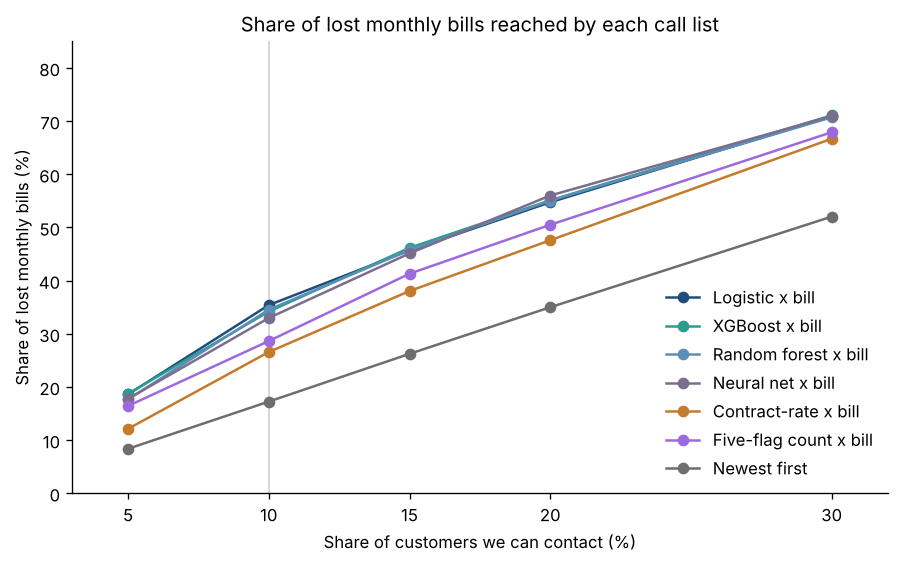

In [9]:
fitted = {name: builder().fit(X_train, y_train) for name, builder in builders.items()}
bill = X_test["MonthlyCharges"].to_numpy(dtype=float)
y_holdout = y_test.to_numpy()
probas = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in fitted.items()}

contract_rates = (
    pd.DataFrame({"Contract": X_train["Contract"].to_numpy(), "churn": y_train.to_numpy()})
    .groupby("Contract")["churn"]
    .mean()
)
scores = {
    "Logistic x bill": probas["logistic regression"] * bill,
    "Random forest x bill": probas["random forest"] * bill,
    "XGBoost x bill": probas["xgboost"] * bill,
    "Neural net x bill": probas["neural network"] * bill,
    "Logistic probability only": probas["logistic regression"],
    "Contract-rate x bill": X_test["Contract"].map(contract_rates).to_numpy(dtype=float) * bill,
    "Five-flag count x bill": flag_count(X_test) * bill,
    "Newest first": contract_tenure_score(X_test["Contract"], X_test["tenure"]),
    "Largest bill": bill,
}

curve_rows = []
for fraction in BUDGETS:
    row = {"quota": f"{fraction:.0%}"}
    for name, score in scores.items():
        if name == "Largest bill":
            continue
        row[name] = capture_share(y_holdout, bill, score, fraction)
    curve_rows.append(row)
curve = pd.DataFrame(curve_rows)
display(percent(curve, [column for column in curve.columns if column != "quota"]))

k = max(1, int(round(len(X_test) * BUDGET)))
lost_bills = bill[y_holdout == 1].sum()
list_rows = []
for name, score in scores.items():
    chosen = np.argsort(-np.asarray(score, dtype=float), kind="mergesort")[:k]
    hits = y_holdout[chosen] == 1
    covered = bill[chosen][hits].sum()
    list_rows.append({
        "list": name,
        "contacts": k,
        "leavers_reached": int(hits.sum()),
        "share_of_calls_who_left": hits.mean(),
        "lost_bills_reached": covered,
        "share_of_lost_bills": covered / lost_bills,
        "mean_bill": bill[chosen].mean(),
        "mean_tenure": X_test.iloc[chosen]["tenure"].mean(),
    })
holdout_lists = pd.DataFrame(list_rows)
display(
    money(
        percent(holdout_lists, ["share_of_calls_who_left", "share_of_lost_bills"]),
        ["lost_bills_reached", "mean_bill"],
    ).assign(mean_tenure=lambda frame: holdout_lists["mean_tenure"].map(lambda value: f"{value:.1f}"))
)

model_score_names = {
    "logistic regression": "Logistic x bill",
    "random forest": "Random forest x bill",
    "xgboost": "XGBoost x bill",
    "neural network": "Neural net x bill",
}
selected_score_name = model_score_names[chosen_name]
print(f"Test customers: {len(X_test):,}. Lost monthly bills: ${lost_bills:,.0f}. Contacts at 10%: {k}.")
print(f"Call list used below: {selected_score_name}")

fig, ax = plt.subplots(figsize=(7.6, 4.8))
plot_specs = [
    ("Logistic x bill", "#1f4e79"),
    ("XGBoost x bill", "#2a9d8f"),
    ("Random forest x bill", "#5b8fb8"),
    ("Neural net x bill", "#7b6d8d"),
    ("Contract-rate x bill", "#c47b2b"),
    ("Five-flag count x bill", "#9c6ade"),
    ("Newest first", "#6e6e6e"),
]
for name, color in plot_specs:
    ax.plot(
        [int(fraction * 100) for fraction in BUDGETS],
        curve[name].map(lambda value: value * 100),
        marker="o",
        color=color,
        label=name,
    )
ax.axvline(10, color="#d0d0d0", lw=1, zorder=0)
ax.set_xticks([5, 10, 15, 20, 30])
ax.set_xlim(3, 32)
ax.set_ylim(0, 85)
ax.set_title("Share of lost monthly bills reached by each call list")
ax.set_xlabel("Share of customers we can contact (%)")
ax.set_ylabel("Share of lost monthly bills (%)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()


In [10]:
rng = np.random.default_rng(RANDOM_STATE)
n_test = len(y_holdout)
B = 2000
boot_scores = {name: score for name, score in scores.items()}


def coverage_on(score, ix, fraction=BUDGET):
    s, b, yy = score[ix], bill[ix], y_holdout[ix]
    kk = max(1, int(round(len(ix) * fraction)))
    chosen = np.argsort(-s, kind="mergesort")[:kk]
    return b[chosen][yy[chosen] == 1].sum() / b[yy == 1].sum()


draws = {name: np.empty(B) for name in boot_scores}
for b_i in range(B):
    ix = rng.integers(0, n_test, n_test)
    for name, score in boot_scores.items():
        draws[name][b_i] = coverage_on(score, ix)

ref = draws["Logistic x bill"]
rows = []
for name, d in draws.items():
    low, high = np.percentile(d, [2.5, 97.5])
    dlow, dhigh = np.percentile(d - ref, [2.5, 97.5])
    rows.append({
        "list": name,
        "coverage_at_10pct": coverage_on(boot_scores[name], np.arange(n_test)),
        "ci_low": low, "ci_high": high,
        "diff_vs_logistic": (coverage_on(boot_scores[name], np.arange(n_test)) - coverage_on(boot_scores["Logistic x bill"], np.arange(n_test))),
        "diff_low": dlow, "diff_high": dhigh,
    })
boot_table = pd.DataFrame(rows)
view = percent(boot_table, ["coverage_at_10pct", "ci_low", "ci_high"])
for column in ["diff_vs_logistic", "diff_low", "diff_high"]:
    view[column] = boot_table[column].map(lambda v: f"{v * 100:+.1f} pp")
display(view)

ceiling_rows = []
leaver_bills_sorted = np.sort(bill[y_holdout == 1])[::-1]
for fraction in BUDGETS:
    kk = max(1, int(round(n_test * fraction)))
    ceiling = leaver_bills_sorted[:kk].sum() / lost_bills
    achieved = curve.loc[curve["quota"] == f"{fraction:.0%}", "Logistic x bill"].iloc[0]
    ceiling_rows.append({"quota": f"{fraction:.0%}", "oracle_ceiling": ceiling, "logistic_x_bill": achieved, "share_of_ceiling": achieved / ceiling})
display(percent(pd.DataFrame(ceiling_rows), ["oracle_ceiling", "logistic_x_bill", "share_of_ceiling"]))
print(
    "Bootstrap: 2,000 resamples of the 1,409 test customers. The oracle ceiling is the lost bills reached "
    "if every one of the call slots went to an actual leaver with one of the largest bills. "
    "It cannot be achieved without knowing who leaves. At a 30% quota the slots outnumber the leavers, so the ceiling reaches 100%."
)


,list,coverage_at_10pct,ci_low,ci_high,diff_vs_logistic,diff_low,diff_high
0,Logistic x bill,35.4%,31.8%,39.0%,+0.0 pp,+0.0 pp,+0.0 pp
1,Random forest x bill,34.6%,30.4%,37.7%,-0.9 pp,-3.7 pp,+1.2 pp
2,XGBoost x bill,34.2%,30.2%,37.2%,-1.2 pp,-4.2 pp,+0.8 pp
3,Neural net x bill,33.0%,29.2%,36.2%,-2.4 pp,-5.5 pp,-0.3 pp
4,Logistic probability only,31.9%,28.3%,35.3%,-3.5 pp,-6.6 pp,-0.7 pp
5,Contract-rate x bill,26.6%,21.9%,29.8%,-8.8 pp,-13.5 pp,-5.4 pp
6,Five-flag count x bill,28.6%,25.3%,32.7%,-6.8 pp,-9.7 pp,-3.2 pp
7,Newest first,17.3%,14.7%,20.2%,-18.2 pp,-22.6 pp,-13.8 pp
8,Largest bill,12.2%,8.9%,16.9%,-23.2 pp,-28.5 pp,-17.3 pp


,quota,oracle_ceiling,logistic_x_bill,share_of_ceiling
0,5%,26.3%,18.6%,70.7%
1,10%,49.9%,35.4%,70.9%
2,15%,70.3%,45.7%,64.9%
3,20%,87.6%,54.7%,62.5%
4,30%,100.0%,70.9%,70.9%


Bootstrap: 2,000 resamples of the 1,409 test customers. The oracle ceiling is the lost bills reached if every one of the call slots went to an actual leaver with one of the largest bills. It cannot be achieved without knowing who leaves. At a 30% quota the slots outnumber the leavers, so the ceiling reaches 100%.


,decile,customers,mean_predicted,share_who_left,standard_error
0,0,141,0.9%,2.1%,1.2%
1,1,141,2.4%,2.1%,1.2%
2,2,141,5.1%,4.3%,1.7%
3,3,141,9.5%,9.9%,2.5%
4,4,141,16.0%,17.0%,3.2%
5,5,140,25.1%,17.1%,3.2%
6,6,141,35.3%,43.3%,4.2%
7,7,141,48.2%,37.6%,4.1%
8,8,141,60.3%,58.2%,4.2%
9,9,141,73.5%,73.8%,3.7%


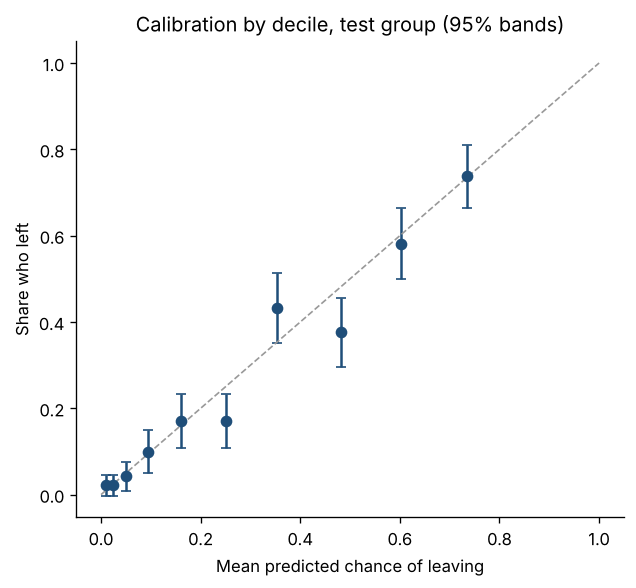

Each decile has about 140 customers, so bands of roughly +/-8 points are normal. The top decile is well calibrated and the lowest deciles are close. Deciles 5 and 6 deviate by 8 points in opposite directions, so quote the probabilities as approximate. The ranking only needs the order to be right.


In [11]:
selected_proba = probas[chosen_name]
cal = pd.DataFrame({"p": selected_proba, "y": y_holdout})
cal["decile"] = pd.qcut(cal["p"], 10, labels=False, duplicates="drop")
cal_table = cal.groupby("decile").agg(customers=("y", "size"), mean_predicted=("p", "mean"), share_who_left=("y", "mean")).reset_index()
cal_table["standard_error"] = np.sqrt(cal_table["share_who_left"] * (1 - cal_table["share_who_left"]) / cal_table["customers"])
display(percent(cal_table, ["mean_predicted", "share_who_left", "standard_error"]))

fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.errorbar(cal_table["mean_predicted"], cal_table["share_who_left"], yerr=1.96 * cal_table["standard_error"], fmt="o", color="#1f4e79", capsize=3)
ax.plot([0, 1], [0, 1], color="#999999", lw=1, linestyle="--")
ax.set_xlabel("Mean predicted chance of leaving")
ax.set_ylabel("Share who left")
ax.set_title("Calibration by decile, test group (95% bands)")
fig.tight_layout()
plt.show()
print("Each decile has about 140 customers, so bands of roughly +/-8 points are normal. The top decile is well calibrated and the lowest deciles are close. Deciles 5 and 6 deviate by 8 points in opposite directions, so quote the probabilities as approximate. The ranking only needs the order to be right.")


,list,logistic regression,random forest,xgboost,neural network
0,logistic regression,100.0%,80.9%,78.7%,79.4%
1,random forest,80.9%,100.0%,87.9%,73.0%
2,xgboost,78.7%,87.9%,100.0%,73.0%
3,neural network,79.4%,73.0%,73.0%,100.0%


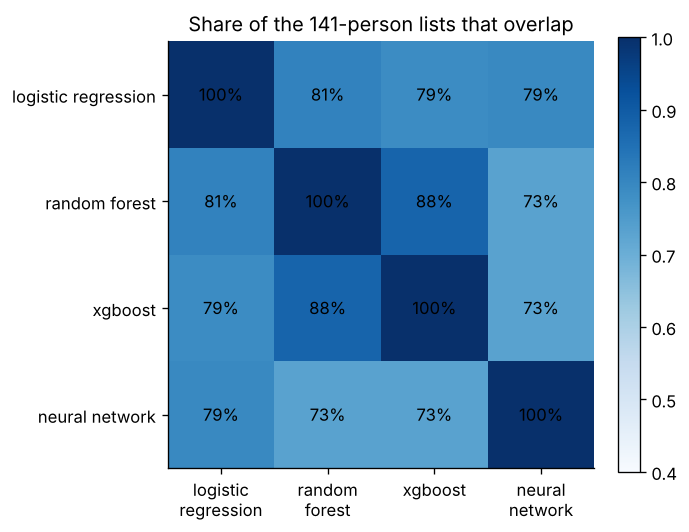

,model,roc_auc,average_precision,brier,precision_at_0.5,recall_at_0.5,f1_at_0.5,flagged_at_0.5
0,logistic regression,0.836,0.640,0.139,0.620,0.551,0.584,0.236
1,random forest,0.840,0.633,0.139,0.673,0.457,0.545,0.180
2,xgboost,0.838,0.647,0.138,0.630,0.537,0.580,0.226
3,neural network,0.833,0.618,0.141,0.646,0.492,0.558,0.202


A 50% cutoff is not the operating rule. The operating rule is the 10% call list.


In [12]:
overlap_names = list(model_score_names.keys())
overlap = pd.DataFrame(index=overlap_names, columns=overlap_names, dtype=float)
tops = {name: top_positions(scores[model_score_names[name]], k) for name in overlap_names}
for left, right in product(overlap_names, overlap_names):
    overlap.loc[left, right] = len(tops[left] & tops[right]) / k
display(percent(overlap.reset_index().rename(columns={"index": "list"}), overlap_names))

fig, ax = plt.subplots(figsize=(5.6, 4.8))
image = ax.imshow(overlap.to_numpy(), cmap="Blues", vmin=0.4, vmax=1)
ax.set_xticks(range(4), [name.replace(" ", "\n") for name in overlap_names])
ax.set_yticks(range(4), overlap_names)
for i, j in product(range(4), range(4)):
    ax.text(j, i, f"{overlap.iat[i, j]:.0%}", ha="center", va="center", color="black")
ax.set_title(f"Share of the {k}-person lists that overlap")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

supporting = []
for name, proba in probas.items():
    predicted = (proba >= 0.5).astype(int)
    supporting.append({
        "model": name,
        "roc_auc": roc_auc_score(y_holdout, proba),
        "average_precision": average_precision_score(y_holdout, proba),
        "brier": brier_score_loss(y_holdout, proba),
        "precision_at_0.5": precision_score(y_holdout, predicted),
        "recall_at_0.5": recall_score(y_holdout, predicted),
        "f1_at_0.5": f1_score(y_holdout, predicted),
        "flagged_at_0.5": predicted.mean(),
    })
display(pd.DataFrame(supporting).round(3))
print("A 50% cutoff is not the operating rule. The operating rule is the 10% call list.")


Two models can have almost the same ranking quality and still call different people. The overlap grid is the check that matters for operations: if the company switched from logistic regression to XGBoost, how much of the queue would change? Overlap of roughly 73-89% means about 11-27% of the queue changes if the model is swapped, even though coverage barely moves.


## 8. Who is on the chosen list?

The selected model fills the 10% queue. The tables below describe those 141 test customers: contract, internet, extras, payment method, tenure, and bill.


In [13]:
selected_score = scores[selected_score_name]
order = np.argsort(-np.asarray(selected_score, dtype=float), kind="mergesort")[:k]
listed = X_test.iloc[order].copy()
listed["churn"] = y_holdout[order]
listed["p_leave"] = probas[chosen_name][order]
listed["monthly_at_risk"] = listed["p_leave"] * listed["MonthlyCharges"]

print(listed["Contract"].value_counts().to_string())
print(listed["InternetService"].replace({"Fiber optic": "Fibre"}).value_counts().to_string())
print("Online security = No:", f"{(listed['OnlineSecurity'] == 'No').mean():.1%}")
print("Tech support = No:", f"{(listed['TechSupport'] == 'No').mean():.1%}")
print("Electronic check:", f"{(listed['PaymentMethod'] == 'Electronic check').mean():.1%}")
print(f"Share who left: {listed['churn'].mean():.1%}")
print(f"Median tenure: {listed['tenure'].median():.0f} months")
print(f"Mean bill: ${listed['MonthlyCharges'].mean():.2f}")

profile_rows = []
for column, values in [
    ("Contract", CONTRACT_ORDER),
    ("InternetService", ["Fiber optic", "DSL", "No"]),
    ("OnlineSecurity", ["No", "Yes"]),
    ("PaymentMethod", None),
]:
    counts = listed[column].value_counts(normalize=True)
    if values is None:
        values = list(counts.index)
    for value in values:
        profile_rows.append({"field": column, "value": value, "share_of_list": float(counts.get(value, 0.0))})
display(percent(pd.DataFrame(profile_rows), ["share_of_list"]))


Contract
Month-to-month    141
InternetService
Fibre    141
Online security = No: 95.7%
Tech support = No: 91.5%
Electronic check: 84.4%
Share who left: 74.5%
Median tenure: 10 months
Mean bill: $92.69


,field,value,share_of_list
0,Contract,Month-to-month,100.0%
1,Contract,One year,0.0%
2,Contract,Two year,0.0%
3,InternetService,Fiber optic,100.0%
4,InternetService,DSL,0.0%
5,InternetService,No,0.0%
6,OnlineSecurity,No,95.7%
7,OnlineSecurity,Yes,4.3%
8,PaymentMethod,Electronic check,84.4%
9,PaymentMethod,Credit card (automatic),5.7%


## 9. Does the selected model make sense?

Permutation importance on the test group shows which fields the ranking actually uses. For logistic regression, coefficients and odds ratios say which way each field points. SHAP explains the selected model's output, including one high-priority customer. SHAP explains the prediction. It does not establish that changing the field would change whether the customer leaves.

Contract type is a ranking signal and may also be an effect: people who have already decided to leave often move to month-to-month first. Electronic check has the same caution.


,field,log_odds_weight,odds_ratio
17,Two-year contract (vs month-to-month),-1.459,0.233
0,Time with the company (scaled),-0.824,0.438
6,Has a phone line,-0.780,0.458
16,One-year contract (vs month-to-month),-0.688,0.503
1,Monthly bill (scaled),0.579,1.784
13,Has tech support,-0.485,0.616
8,Fibre internet (vs DSL),0.448,1.565
10,Has online security,-0.441,0.643
18,Paperless billing,0.318,1.374
9,No internet (vs DSL),-0.297,0.743


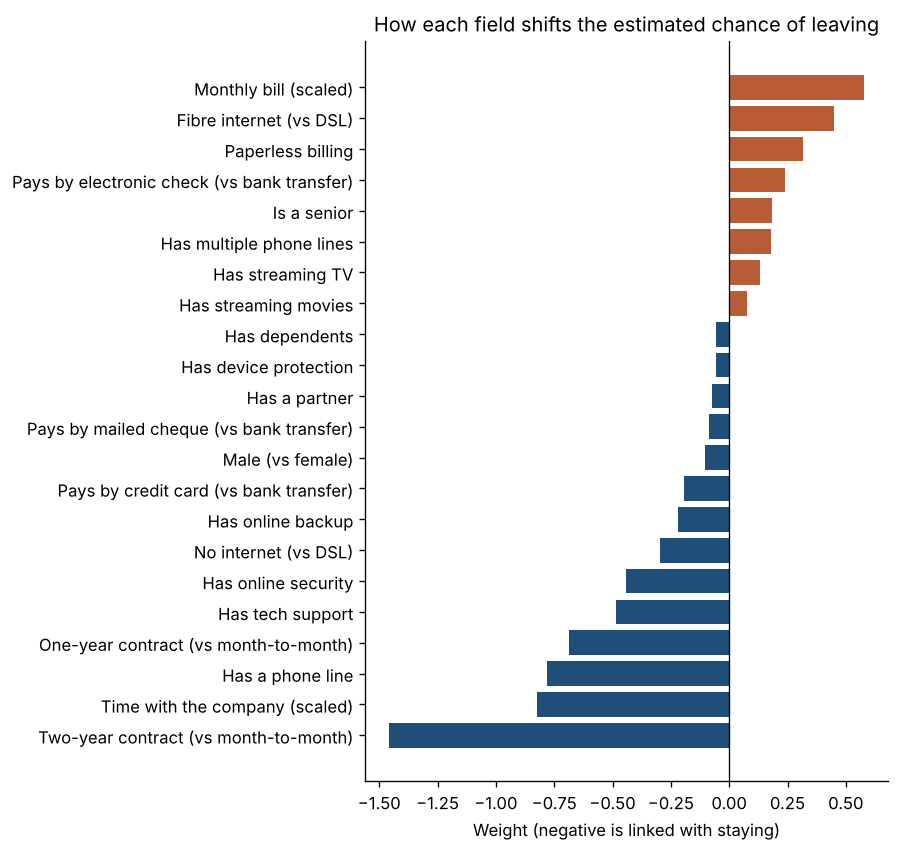

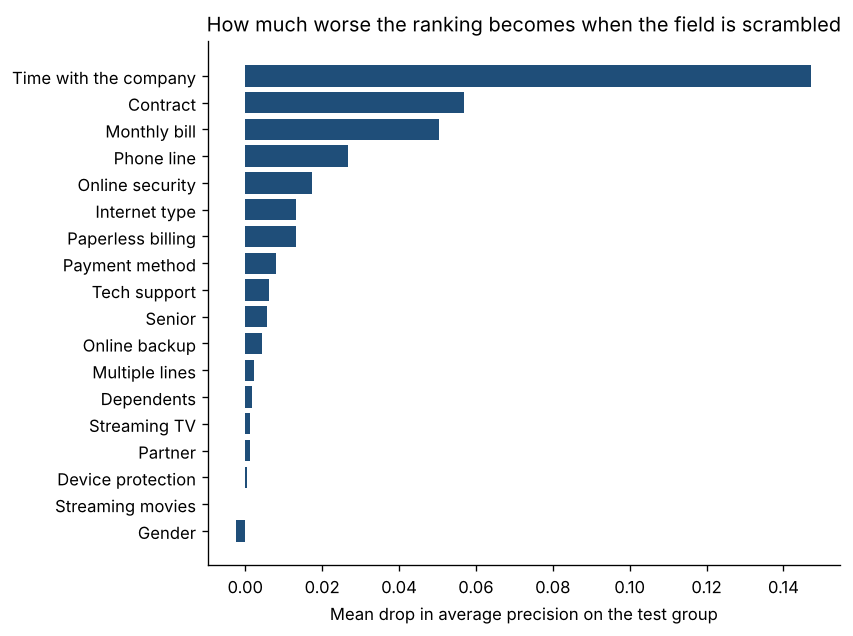

In [14]:
selected_model = fitted[chosen_name]
feature_names = (
    ["tenure", "MonthlyCharges", "SeniorCitizen"]
    + list(selected_model.named_steps["preprocess"].named_transformers_["categorical"].get_feature_names_out(CATEGORICAL))
)
friendly = {
    "tenure": "Time with the company (scaled)",
    "MonthlyCharges": "Monthly bill (scaled)",
    "SeniorCitizen": "Is a senior",
    "gender_Male": "Male (vs female)",
    "Partner_Yes": "Has a partner",
    "Dependents_Yes": "Has dependents",
    "PhoneService_Yes": "Has a phone line",
    "MultipleLines_Yes": "Has multiple phone lines",
    "InternetService_Fiber optic": "Fibre internet (vs DSL)",
    "InternetService_No": "No internet (vs DSL)",
    "OnlineSecurity_Yes": "Has online security",
    "OnlineBackup_Yes": "Has online backup",
    "DeviceProtection_Yes": "Has device protection",
    "TechSupport_Yes": "Has tech support",
    "StreamingTV_Yes": "Has streaming TV",
    "StreamingMovies_Yes": "Has streaming movies",
    "Contract_One year": "One-year contract (vs month-to-month)",
    "Contract_Two year": "Two-year contract (vs month-to-month)",
    "PaperlessBilling_Yes": "Paperless billing",
    "PaymentMethod_Credit card (automatic)": "Pays by credit card (vs bank transfer)",
    "PaymentMethod_Electronic check": "Pays by electronic check (vs bank transfer)",
    "PaymentMethod_Mailed check": "Pays by mailed cheque (vs bank transfer)",
}

if chosen_name == "logistic regression":
    coef = pd.Series(selected_model.named_steps["model"].coef_.ravel(), index=feature_names)
    odds = np.exp(coef)
    coef_table = pd.DataFrame({
        "field": [friendly.get(name, name) for name in coef.index],
        "log_odds_weight": coef.values,
        "odds_ratio": odds.values,
    }).assign(abs_weight=lambda frame: frame["log_odds_weight"].abs())
    coef_table = coef_table.sort_values("abs_weight", ascending=False).drop(columns="abs_weight")
    display(coef_table.round(3))

    labeled = coef.rename(friendly).sort_values()
    fig, ax = plt.subplots(figsize=(7.6, 7.2))
    colors = ["#1f4e79" if value < 0 else "#b85c38" for value in labeled]
    ax.barh(labeled.index, labeled.values, color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title("How each field shifts the estimated chance of leaving")
    ax.set_xlabel("Weight (negative is linked with staying)")
    fig.tight_layout()
    plt.show()

column_labels = {
    "tenure": "Time with the company",
    "Contract": "Contract",
    "MonthlyCharges": "Monthly bill",
    "PhoneService": "Phone line",
    "OnlineSecurity": "Online security",
    "InternetService": "Internet type",
    "PaperlessBilling": "Paperless billing",
    "PaymentMethod": "Payment method",
    "TechSupport": "Tech support",
    "SeniorCitizen": "Senior",
    "OnlineBackup": "Online backup",
    "MultipleLines": "Multiple lines",
    "Dependents": "Dependents",
    "Partner": "Partner",
    "StreamingTV": "Streaming TV",
    "DeviceProtection": "Device protection",
    "StreamingMovies": "Streaming movies",
    "gender": "Gender",
}
importance = permutation_importance(
    selected_model, X_test, y_test, n_repeats=12, random_state=RANDOM_STATE,
    scoring="average_precision", n_jobs=1,
)
importance_table = (
    pd.Series(importance.importances_mean, index=X_test.columns)
    .rename(column_labels)
    .sort_values(ascending=True)
)
fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.barh(importance_table.index, importance_table.values, color="#1f4e79")
ax.set_title("How much worse the ranking becomes when the field is scrambled")
ax.set_xlabel("Mean drop in average precision on the test group")
fig.tight_layout()
plt.show()


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


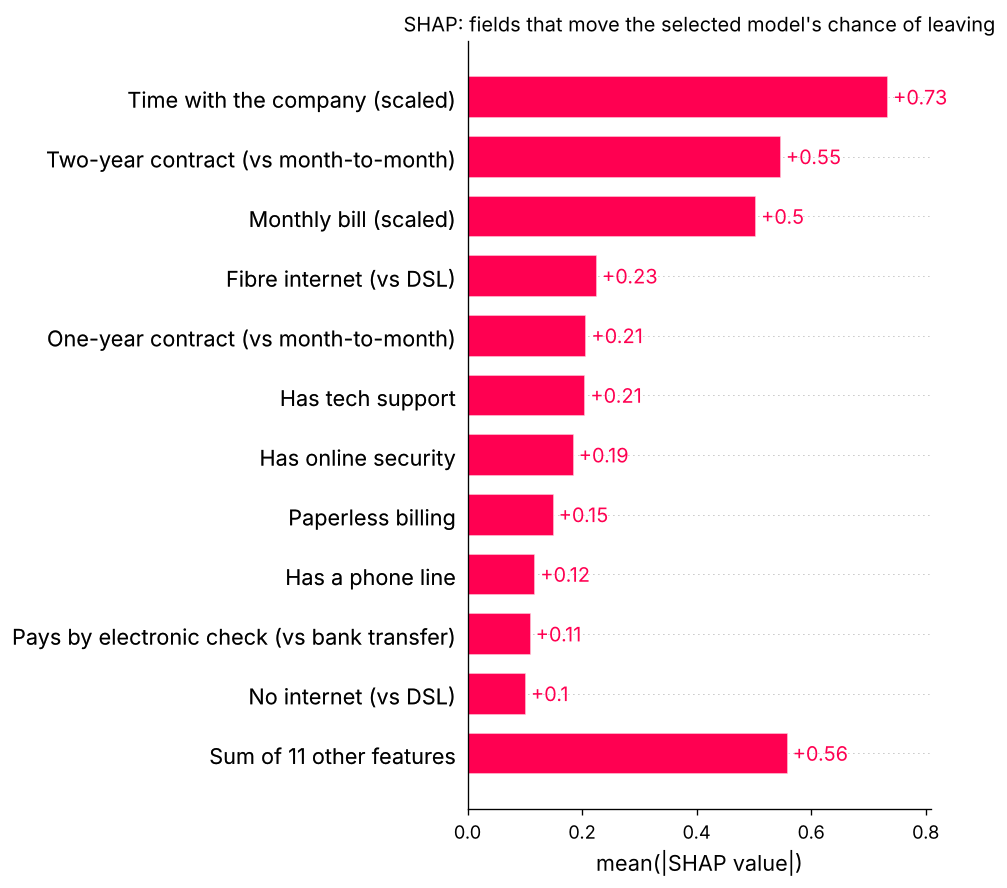

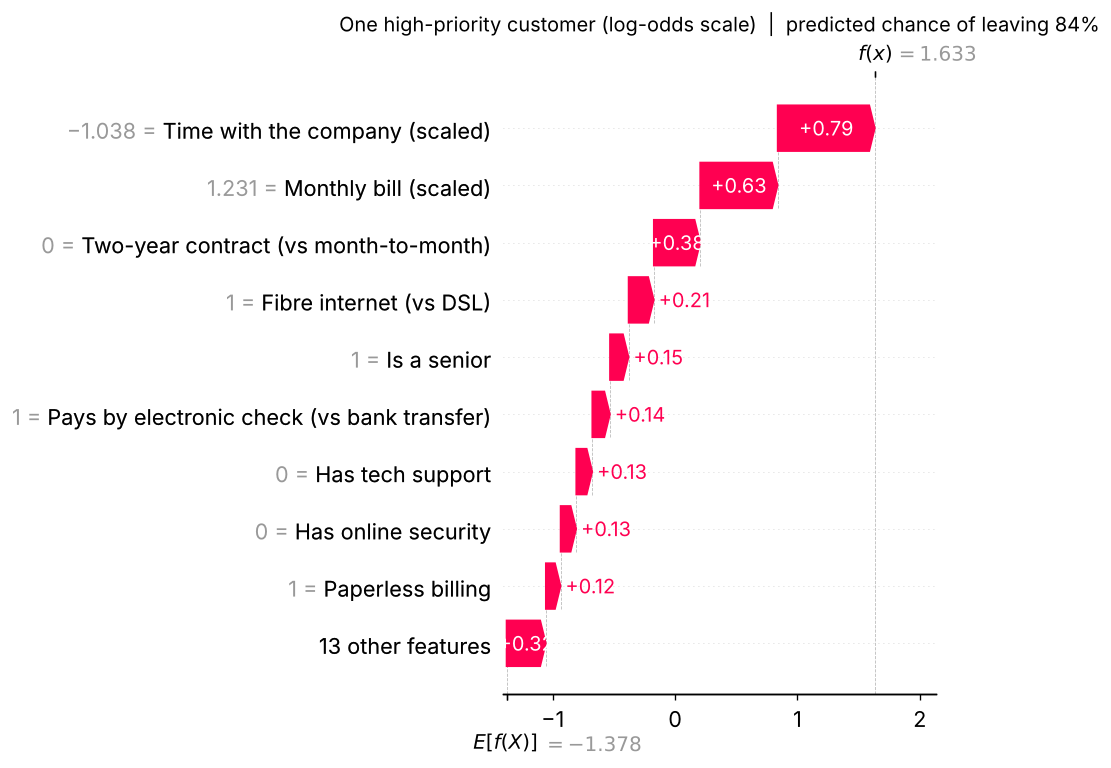

SHAP explains this model's output. It is not a claim that changing the field would keep the customer.


In [15]:
preprocess = selected_model.named_steps["preprocess"]
clf = selected_model.named_steps["model"]
X_test_trans = preprocess.transform(X_test)
rng = np.random.RandomState(RANDOM_STATE)
bg_idx = rng.choice(len(X_test_trans), size=min(200, len(X_test_trans)), replace=False)
background = X_test_trans[bg_idx]
explain_n = min(200, len(X_test_trans))
X_explain = X_test_trans[:explain_n]
readable_names = [friendly.get(name, name) for name in feature_names]


def attach_names(values):
    values.feature_names = readable_names
    return values


if chosen_name in {"random forest", "xgboost"}:
    explainer = shap.TreeExplainer(clf, data=background)
    shap_values = attach_names(explainer(X_explain))
    if getattr(shap_values, "values").ndim == 3:
        shap_values = shap_values[..., 1]
elif chosen_name == "logistic regression":
    explainer = shap.LinearExplainer(clf, background)
    shap_values = attach_names(explainer(X_explain))
else:
    explainer = shap.PermutationExplainer(clf.predict_proba, background)
    shap_values = attach_names(explainer(X_explain))
    if getattr(shap_values, "values").ndim == 3:
        shap_values = shap_values[..., 1]

shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("SHAP: fields that move the selected model's chance of leaving")
plt.tight_layout()
plt.show()

priority_row = int(order[0])
one_row = X_test_trans[priority_row:priority_row + 1]
one_shap = attach_names(explainer(one_row))
if getattr(one_shap, "values").ndim == 3:
    one_shap = one_shap[..., 1]
shap.plots.waterfall(one_shap[0], max_display=10, show=False)
plt.title(
    f"One high-priority customer (log-odds scale)  |  predicted chance of leaving {probas[chosen_name][priority_row]:.0%}"
)
plt.tight_layout()
plt.show()
print("SHAP explains this model's output. It is not a claim that changing the field would keep the customer.")


Inside a single internet type, a higher bill goes with **fewer** leavers, yet the logistic weight on the monthly bill is positive. Both can be true: the bill is almost a sum of the services a customer has, so once fibre and the extras are in the model the bill column carries only the leftover variation. The check below measures how much of the bill the other fields already explain. Where that share is very high, individual coefficients (the bill, the phone-line flag, the extras) are not stable and should not be read as stand-alone effects. The ranking is much more stable than any single weight.

Training customers


,InternetService,bill_group,customers,share_who_left
0,DSL,Cheapest quarter,480,32.3%
1,DSL,Second,483,23.6%
2,DSL,Third,478,11.1%
3,DSL,Most expensive quarter,478,6.5%
4,Fibre,Cheapest quarter,623,56.3%
5,Fibre,Second,619,45.7%
6,Fibre,Third,625,40.0%
7,Fibre,Most expensive quarter,615,26.7%


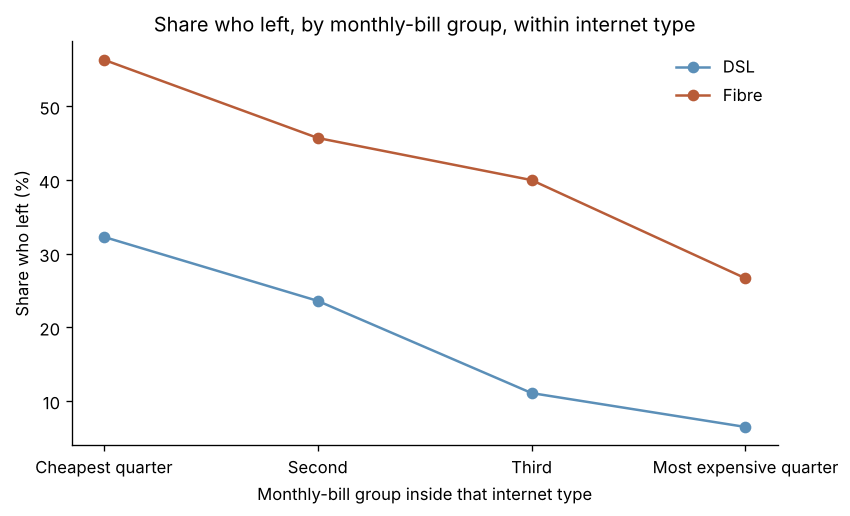

In [16]:
def bill_quartiles(features, target):
    frame = features.copy()
    frame["churn"] = np.asarray(target)
    frame = frame[frame["InternetService"].isin(["DSL", "Fiber optic"])].copy()
    frame["bill_group"] = frame.groupby("InternetService")["MonthlyCharges"].transform(
        lambda series: pd.qcut(series, 4, labels=["Cheapest quarter", "Second", "Third", "Most expensive quarter"])
    )
    table = (
        frame.groupby(["InternetService", "bill_group"], observed=True)["churn"]
        .agg(customers="size", share_who_left="mean")
        .reset_index()
    )
    table["InternetService"] = table["InternetService"].replace({"Fiber optic": "Fibre"})
    return table


print("Training customers")
display(percent(bill_quartiles(X_train, y_train), ["share_who_left"]))
train_q = bill_quartiles(X_train, y_train)
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for service, color in [("DSL", "#5b8fb8"), ("Fibre", "#b85c38")]:
    part = train_q[train_q["InternetService"] == service]
    ax.plot(part["bill_group"].astype(str), part["share_who_left"] * 100, marker="o", color=color, label=service)
ax.set_title("Share who left, by monthly-bill group, within internet type")
ax.set_xlabel("Monthly-bill group inside that internet type")
ax.set_ylabel("Share who left (%)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


In [17]:
from sklearn.linear_model import LinearRegression

others = ColumnTransformer([
    ("num", "passthrough", ["tenure", "SeniorCitizen"]),
    ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), CATEGORICAL),
])
Z = others.fit_transform(X_train)
r2 = LinearRegression().fit(Z, X_train["MonthlyCharges"]).score(Z, X_train["MonthlyCharges"])
print(f"Share of the monthly bill explained by all the other fields: {r2:.1%}")

# Does the ranking survive dropping the bill from the probability model?
no_bill = make_pipeline(LogisticRegression(max_iter=2000, solver="lbfgs", **logistic_params))
no_bill.named_steps["preprocess"].transformers[0] = ("numeric", StandardScaler(), ["tenure"])
nb_result = fold_capture(no_bill, X_train, y_train, BUDGET)
print(
    f"10% coverage on the folds: logistic with the bill {logistic_cv['shares'].mean():.1%}, "
    f"logistic without the bill as a feature {nb_result['shares'].mean():.1%}. "
    "The bill still multiplies the score either way."
)


Share of the monthly bill explained by all the other fields: 99.9%


10% coverage on the folds: logistic with the bill 33.4%, logistic without the bill as a feature 33.5%. The bill still multiplies the score either way.


### Sensitive fields

`gender` and `SeniorCitizen` are inputs to the scoring models. Using them to decide who receives a retention discount or a contract offer can raise fairness and regulatory questions depending on the market. The check below refits logistic regression without them. If the coverage is unchanged, they can be dropped at no cost to the call list.

In [18]:
def make_pipeline_subset(estimator, drop):
    cats = [c for c in CATEGORICAL if c not in drop]
    transformers = [("numeric", StandardScaler(), ["tenure", "MonthlyCharges"])]
    if "SeniorCitizen" not in drop:
        transformers.append(("senior", "passthrough", ["SeniorCitizen"]))
    transformers.append(("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cats))
    return Pipeline([("preprocess", ColumnTransformer(transformers)), ("model", estimator)])


dropped = ["gender", "SeniorCitizen"]
subset = fold_capture(
    make_pipeline_subset(LogisticRegression(max_iter=2000, solver="lbfgs", **logistic_params), dropped),
    X_train, y_train, BUDGET,
)
paired = subset["shares"] - logistic_cv["shares"]
print(
    f"10% coverage on the folds: all fields {logistic_cv['shares'].mean():.1%}, "
    f"without gender and senior status {subset['shares'].mean():.1%} "
    f"(difference {paired.mean() * 100:+.2f} points, fold range {paired.min() * 100:+.2f} to {paired.max() * 100:+.2f})."
)


10% coverage on the folds: all fields 33.4%, without gender and senior status 33.5% (difference +0.09 points, fold range -0.45 to +0.60).


## 10. Customer types and different keep-offers

The call list says who to phone. It does not say what to offer them. Three customer types are defined from the fields the ranking uses. A customer can match more than one description, so a priority rule gives each person one script:

1. **Stable.** One-year or two-year contract, and at least 24 months with the company. Not a save-call target.
2. **New high-value.** Month-to-month, 12 months or fewer, and a monthly bill of at least $70. The month-to-month median bill is about $73, so $70 is a round cut, not a number tuned on the test customers.
3. **High-risk service.** Fibre, no online security, and no tech support, and not already assigned above.
4. **Other.** Everyone else.

Stable customers are assigned first. In the training sample 190 of them also have unprotected fibre, but only about one in five leaves, so they must not inherit the save script.

The offers are hypotheses to test, not findings. Having security or tech support goes with staying, but engaged customers may simply be the ones who bought them, so this file cannot say that adding them keeps anyone. It has no record of past offers. This file has no record of past offers, so it cannot say which script would keep anyone.


Overlapping descriptions, training customers


,description,customers,share_who_left,mean_tenure,mean_bill,share_of_training_lost_bills
0,New high-value (overlapping),697,69.6%,5.0,$83.16,36.4%
1,High-risk service (overlapping),1395,55.8%,23.4,$86.13,59.4%
2,Stable (overlapping),2213,6.8%,55.8,$66.89,12.0%
3,New high-value and high-risk service,547,73.9%,4.7,$82.31,30.0%
4,Stable and high-risk service,190,20.5%,56.2,$95.69,3.4%


One script each, training customers. Stable is assigned first, then new high-value, then high-risk service.


,segment,customers,share_of_customers,share_who_left,mean_tenure,mean_bill,share_of_lost_bills,share_fibre_no_extras
0,New high-value,697,12.4%,69.6%,5.0,$83.16,36.4%,78.5%
1,High-risk service,658,11.7%,50.9%,29.5,$86.55,26.0%,100.0%
2,Stable,2213,39.3%,6.8%,55.8,$66.89,12.0%,8.6%
3,Other,2066,36.7%,25.4%,17.9,$49.38,25.6%,0.0%


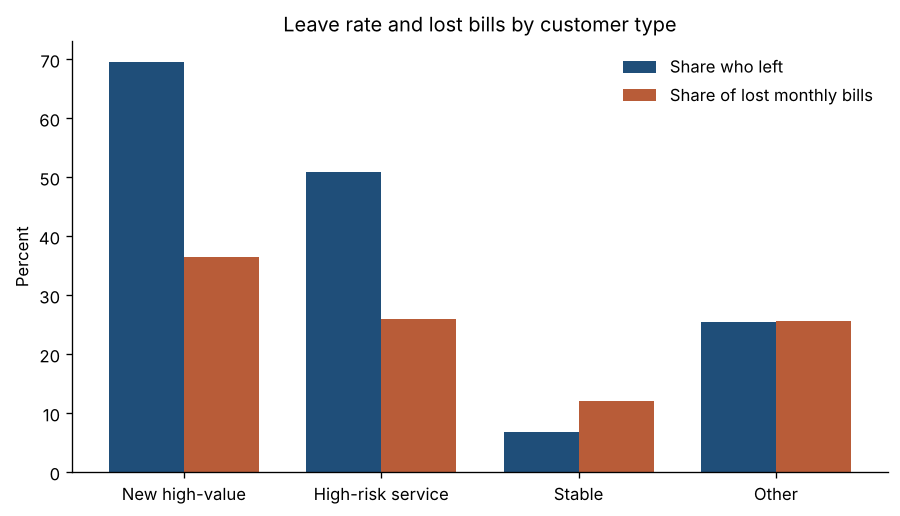

Same rules on the test call list


,segment,contacts,share_of_call_list,leavers,lost_bills,share_of_list_lost_bills,mean_tenure,mean_bill,cost_at_20,break_even_save_rate
0,New high-value,80,56.7%,62,"$5,520.65",57.0%,5.0,$89.21,"$1,600.00",29.0%
1,High-risk service,50,35.5%,34,"$3,273.10",33.8%,26.8,$96.39,"$1,000.00",30.6%
2,Stable,0,0.0%,0,$0.00,0.0%,,,$0.00,
3,Other,11,7.8%,9,$898.70,9.3%,24.7,$101.20,$220.00,24.5%


,segment,offer to test,why this offer,do not
0,New high-value,Move them onto a one-year contract that includ...,"They are new, on a flexible contract, and alre...",Open with a permanent discount. The bill is hi...
1,High-risk service,"Turn on online security and tech support, with...",They have already stayed longer on unprotected...,Use the new-customer contract script.
2,Stable,No save call. A renewal reminder only near the...,Few of them leave. The 10% quota is better spe...,Spend a scarce save slot or a discount here.
3,Other,No standard script. Review the few who reach t...,On the call list these are high bills that alr...,Copy the fibre-extras script onto an account t...


A 3-cluster k-means on the same fields puts the call list into 1 cluster(s): 1=141. It cannot assign different offers, so the rules above are the operating segmentation.


In [19]:
SEGMENT_ORDER = ["New high-value", "High-risk service", "Stable", "Other"]


def segment_frame(frame):
    out = frame.copy()
    out["new_high_value"] = (
        (out["Contract"] == "Month-to-month")
        & (out["tenure"] <= 12)
        & (out["MonthlyCharges"] >= 70)
    )
    out["high_risk_service"] = (
        (out["InternetService"] == "Fiber optic")
        & (out["OnlineSecurity"] == "No")
        & (out["TechSupport"] == "No")
    )
    out["stable_flag"] = out["Contract"].isin(["One year", "Two year"]) & (out["tenure"] >= 24)
    out["segment"] = np.select(
        [out["stable_flag"], out["new_high_value"], out["high_risk_service"]],
        ["Stable", "New high-value", "High-risk service"],
        default="Other",
    )
    return out


def segment_profile(frame, churn):
    work = frame.copy()
    work["churn"] = np.asarray(churn)
    lost = work.loc[work["churn"] == 1, "MonthlyCharges"].sum()
    rows = []
    for name in SEGMENT_ORDER:
        part = work[work["segment"] == name]
        left = part[part["churn"] == 1]
        rows.append({
            "segment": name,
            "customers": int(len(part)),
            "share_of_customers": len(part) / len(work),
            "share_who_left": part["churn"].mean(),
            "mean_tenure": part["tenure"].mean(),
            "mean_bill": part["MonthlyCharges"].mean(),
            "share_of_lost_bills": left["MonthlyCharges"].sum() / lost,
            "share_fibre_no_extras": part["high_risk_service"].mean(),
        })
    return pd.DataFrame(rows)


train_segments = segment_frame(X_train)
overlap_rows = []
for name, mask in [
    ("New high-value (overlapping)", train_segments["new_high_value"]),
    ("High-risk service (overlapping)", train_segments["high_risk_service"]),
    ("Stable (overlapping)", train_segments["stable_flag"]),
    ("New high-value and high-risk service", train_segments["new_high_value"] & train_segments["high_risk_service"]),
    ("Stable and high-risk service", train_segments["stable_flag"] & train_segments["high_risk_service"]),
]:
    part = train_segments[mask]
    left = y_train.loc[part.index] == 1
    overlap_rows.append({
        "description": name,
        "customers": int(len(part)),
        "share_who_left": float(y_train.loc[part.index].mean()),
        "mean_tenure": part["tenure"].mean(),
        "mean_bill": part["MonthlyCharges"].mean(),
        "share_of_training_lost_bills": part.loc[left, "MonthlyCharges"].sum() / X_train.loc[y_train == 1, "MonthlyCharges"].sum(),
    })
print("Overlapping descriptions, training customers")
overlap = pd.DataFrame(overlap_rows)
display(
    money(percent(overlap, ["share_who_left", "share_of_training_lost_bills"]), ["mean_bill"])
    .assign(mean_tenure=lambda frame: overlap["mean_tenure"].map(lambda value: f"{value:.1f}"))
)

print("One script each, training customers. Stable is assigned first, then new high-value, then high-risk service.")
train_exclusive = segment_profile(train_segments, y_train)
display(
    money(
        percent(train_exclusive, ["share_of_customers", "share_who_left", "share_of_lost_bills", "share_fibre_no_extras"]),
        ["mean_bill"],
    ).assign(mean_tenure=lambda frame: train_exclusive["mean_tenure"].map(lambda value: f"{value:.1f}"))
)

fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(SEGMENT_ORDER))
width = 0.38
ax.bar(x - width / 2, train_exclusive["share_who_left"] * 100, width, color="#1f4e79", label="Share who left")
ax.bar(x + width / 2, train_exclusive["share_of_lost_bills"] * 100, width, color="#b85c38", label="Share of lost monthly bills")
ax.set_xticks(x, SEGMENT_ORDER)
ax.set_ylabel("Percent")
ax.set_title("Leave rate and lost bills by customer type")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

call_segments = segment_frame(listed)
call_lost = call_segments.loc[call_segments["churn"] == 1, "MonthlyCharges"].sum()
call_rows = []
for name in SEGMENT_ORDER:
    part = call_segments[call_segments["segment"] == name]
    left = part[part["churn"] == 1]
    segment_lost = float(left["MonthlyCharges"].sum())
    contacts_in_segment = int(len(part))
    call_rows.append({
        "segment": name,
        "contacts": contacts_in_segment,
        "share_of_call_list": contacts_in_segment / len(call_segments),
        "leavers": int(len(left)),
        "lost_bills": segment_lost,
        "share_of_list_lost_bills": segment_lost / call_lost,
        "mean_tenure": part["tenure"].mean() if contacts_in_segment else np.nan,
        "mean_bill": part["MonthlyCharges"].mean() if contacts_in_segment else np.nan,
        "cost_at_20": contacts_in_segment * 20,
        "break_even_save_rate": (contacts_in_segment * 20) / segment_lost if segment_lost else np.nan,
    })
call_segment_table = pd.DataFrame(call_rows)
print("Same rules on the test call list")
call_view = money(
    percent(call_segment_table, ["share_of_call_list", "share_of_list_lost_bills", "break_even_save_rate"]),
    ["lost_bills", "cost_at_20"],
)
call_view["mean_tenure"] = call_segment_table["mean_tenure"].map(lambda value: "" if pd.isna(value) else f"{value:.1f}")
call_view["mean_bill"] = call_segment_table["mean_bill"].map(lambda value: "" if pd.isna(value) else f"${value:,.2f}")
display(call_view)

offers = pd.DataFrame([
    {
        "segment": "New high-value",
        "offer to test": "Move them onto a one-year contract that includes online security and tech support for that term.",
        "why this offer": "They are new, on a flexible contract, and already on a high bill. Most of them also have unprotected fibre.",
        "do not": "Open with a permanent discount. The bill is high because the service is high.",
    },
    {
        "segment": "High-risk service",
        "offer to test": "Turn on online security and tech support, with a one-time credit if they accept.",
        "why this offer": "They have already stayed longer on unprotected fibre. A working hypothesis is that the missing extras, not the contract, are the gap. Test it against a control group.",
        "do not": "Use the new-customer contract script.",
    },
    {
        "segment": "Stable",
        "offer to test": "No save call. A renewal reminder only near the end of the contract, and only with spare capacity.",
        "why this offer": "Few of them leave. The 10% quota is better spent on the two groups above.",
        "do not": "Spend a scarce save slot or a discount here.",
    },
    {
        "segment": "Other",
        "offer to test": "No standard script. Review the few who reach the call list one by one.",
        "why this offer": "On the call list these are high bills that already have security or tech support, so neither script above fits.",
        "do not": "Copy the fibre-extras script onto an account that already has one.",
    },
])
display(offers)

cluster_source = X_train.copy()
cluster_source["month_to_month"] = (cluster_source["Contract"] == "Month-to-month").astype(int)
cluster_source["fibre"] = (cluster_source["InternetService"] == "Fiber optic").astype(int)
cluster_source["no_security"] = (cluster_source["OnlineSecurity"] == "No").astype(int)
cluster_source["no_tech"] = (cluster_source["TechSupport"] == "No").astype(int)
cluster_fields = ["tenure", "MonthlyCharges", "month_to_month", "fibre", "no_security", "no_tech"]
scaler = StandardScaler()
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(scaler.fit_transform(cluster_source[cluster_fields]))
listed_cluster = listed.copy()
listed_cluster["month_to_month"] = (listed_cluster["Contract"] == "Month-to-month").astype(int)
listed_cluster["fibre"] = (listed_cluster["InternetService"] == "Fiber optic").astype(int)
listed_cluster["no_security"] = (listed_cluster["OnlineSecurity"] == "No").astype(int)
listed_cluster["no_tech"] = (listed_cluster["TechSupport"] == "No").astype(int)
listed_labels = kmeans.predict(scaler.transform(listed_cluster[cluster_fields]))
print(
    "A 3-cluster k-means on the same fields puts the call list into "
    f"{len(set(listed_labels))} cluster(s): "
    + ", ".join(f"{label}={count}" for label, count in zip(*np.unique(listed_labels, return_counts=True)))
    + ". It cannot assign different offers, so the rules above are the operating segmentation."
)


On the training customers, new high-value and high-risk service are different problems that often sit on the same person. About four in five new high-value customers also have unprotected fibre. The priority rule still gives those people the contract-conversion script, and the two extras are part of that offer. Customers who are unprotected-fibre but no longer new get the extras without being asked to sign a new contract. Stable customers, including the ones who also lack security, stay off the save queue.

The test call list follows that split. Most of the 141 contacts are new high-value. A smaller group are longer-tenure unprotected fibre. None are stable. A handful already have security or tech support, so neither script fits and they are reviewed one by one.

A 3-cluster fit on the same fields puts the whole call list in one cluster. That is why the offers use these rules rather than the clusters. The rules describe who to treat differently. They do not estimate the effect of the offer.

## 11. Is contacting them worth the cost?

The list maximises lost monthly bills reached. It does not measure whether an offer would keep anyone. The save rate cannot be estimated from this file. Each scenario assumes a contact costs a fixed amount and a share of the leavers who were contacted stay for **one extra month**. Remaining life is treated as equal across customers except through the current bill. If some saved customers would stay for years and others for weeks, the ranking would change. A one-month credit is the most conservative case, so most tables below show a loss on purpose. The extra table that follows shows how quickly that flips when a saved customer stays longer. The $20 contact cost is a placeholder. Offer discounts given to contacts who would have stayed are not costed here.

The first table varies the contact quota from 5% to 30% at $20 per contact. The second holds the quota at 10% and varies the cost.


In [20]:
model_row = holdout_lists.loc[holdout_lists["list"] == selected_score_name].iloc[0]
contract_row = holdout_lists.loc[holdout_lists["list"] == "Contract-rate x bill"].iloc[0]
contacts = int(model_row["contacts"])
lost_on_list = float(model_row["lost_bills_reached"])
leavers_reached = int(model_row["leavers_reached"])
extra_vs_contract = lost_on_list - float(contract_row["lost_bills_reached"])

budget_rows = []
for fraction in BUDGETS:
    contacts_at = max(1, int(round(len(X_test) * fraction)))
    chosen = np.argsort(-np.asarray(scores[selected_score_name], dtype=float), kind="mergesort")[:contacts_at]
    covered = float(bill[chosen][y_holdout[chosen] == 1].sum())
    programme = contacts_at * 20
    budget_rows.append({
        "quota": f"{fraction:.0%}",
        "contacts": contacts_at,
        "lost_bills_reached": covered,
        "share_of_lost_bills": covered / lost_bills,
        "cost_at_20": programme,
        "break_even_save_rate": programme / covered,
        "net_if_20pct_stay_one_month": 0.20 * covered - programme,
        "net_if_40pct_stay_one_month": 0.40 * covered - programme,
    })
budget_value = pd.DataFrame(budget_rows)
print("Each quota at $20 per contact. The 20% and 40% columns assume that share of listed leavers stay one extra month.")
display(
    money(
        percent(budget_value, ["share_of_lost_bills", "break_even_save_rate"]),
        ["lost_bills_reached", "cost_at_20"],
    ).assign(
        net_if_20pct_stay_one_month=lambda frame: budget_value["net_if_20pct_stay_one_month"].map("${:,.0f}".format),
        net_if_40pct_stay_one_month=lambda frame: budget_value["net_if_40pct_stay_one_month"].map("${:,.0f}".format),
    )
)

rows = []
for cost in (10, 20, 30, 50):
    rows.append({
        "cost_per_contact": cost,
        "programme_cost": contacts * cost,
        "break_even_share_of_listed_leavers": (contacts * cost) / lost_on_list,
        "net_if_20pct_stay_one_month": 0.20 * lost_on_list - contacts * cost,
        "net_if_40pct_stay_one_month": 0.40 * lost_on_list - contacts * cost,
    })
break_even = pd.DataFrame(rows)
display(
    break_even.assign(
        cost_per_contact=lambda frame: frame["cost_per_contact"].map("${:,.0f}".format),
        programme_cost=lambda frame: frame["programme_cost"].map("${:,.0f}".format),
        break_even_share_of_listed_leavers=lambda frame: frame["break_even_share_of_listed_leavers"].map("{:.1%}".format),
        net_if_20pct_stay_one_month=lambda frame: frame["net_if_20pct_stay_one_month"].map("${:,.0f}".format),
        net_if_40pct_stay_one_month=lambda frame: frame["net_if_40pct_stay_one_month"].map("${:,.0f}".format),
    )
)
print(
    f"Lost bills on the chosen list: ${lost_on_list:,.0f} from {leavers_reached} leavers. "
    f"Extra versus the contract-rate list: ${extra_vs_contract:,.0f}, at the same {contacts} contacts."
)
print("The 20% and 40% columns are assumptions, not estimates.")


Each quota at $20 per contact. The 20% and 40% columns assume that share of listed leavers stay one extra month.


,quota,contacts,lost_bills_reached,share_of_lost_bills,cost_at_20,break_even_save_rate,net_if_20pct_stay_one_month,net_if_40pct_stay_one_month
0,5%,70,"$5,096.80",18.6%,"$1,400.00",27.5%,$-381,$639
1,10%,141,"$9,692.45",35.4%,"$2,820.00",29.1%,$-882,"$1,057"
2,15%,211,"$12,506.45",45.7%,"$4,220.00",33.7%,"$-1,719",$783
3,20%,282,"$14,987.90",54.7%,"$5,640.00",37.6%,"$-2,642",$355
4,30%,423,"$19,415.45",70.9%,"$8,460.00",43.6%,"$-4,577",$-694


,cost_per_contact,programme_cost,break_even_share_of_listed_leavers,net_if_20pct_stay_one_month,net_if_40pct_stay_one_month
0,$10,"$1,410",14.5%,$528,"$2,467"
1,$20,"$2,820",29.1%,$-882,"$1,057"
2,$30,"$4,230",43.6%,"$-2,292",$-353
3,$50,"$7,050",72.7%,"$-5,112","$-3,173"


Lost bills on the chosen list: $9,692 from 105 leavers. Extra versus the contract-rate list: $2,415, at the same 141 contacts.
The 20% and 40% columns are assumptions, not estimates.


In [21]:
rows = []
for months in (1, 3, 6, 12):
    row = {"months_a_saved_customer_stays": months}
    for save in (0.10, 0.20, 0.30):
        row[f"net_at_{int(save * 100)}pct_saved"] = save * lost_on_list * months - contacts * 20
    rows.append(row)
months_table = pd.DataFrame(rows)
display(months_table.assign(**{c: months_table[c].map("${:,.0f}".format) for c in months_table.columns if c.startswith("net")}))
print("Scenarios at the 10% quota and $20 per contact. Share saved and months retained are both assumptions. Positive means the contacts pay for themselves under that assumption.")


,months_a_saved_customer_stays,net_at_10pct_saved,net_at_20pct_saved,net_at_30pct_saved
0,1,"$-1,851",$-882,$88
1,3,$88,"$2,995","$5,903"
2,6,"$2,995","$8,811","$14,626"
3,12,"$8,811","$20,442","$32,073"


Scenarios at the 10% quota and $20 per contact. Share saved and months retained are both assumptions. Positive means the contacts pay for themselves under that assumption.


### 11b. Expected profit: how many customers is it worth calling?

The coverage metric counts the monthly bills of leavers on the list. It does not weigh the **reward from a customer who is kept** against the **cost of keeping them**, and it takes the 10% quota as given. This section values every call and lets the number of calls follow from the economics.

For a contacted customer *i* with predicted chance of leaving $p_i$ and monthly bill $b_i$:

$$
\text{expected value}_i = p_i \cdot s \cdot (m \cdot b_i - k) \;-\; (1 - p_i) \cdot a \cdot k \;-\; c
$$

| Symbol | Meaning | Values tried |
|---|---|---|
| $s$ | save rate: share of contacted would-be leavers who are kept | 10%, 20%, 30%, 40% |
| $m$ | months a saved customer keeps paying | 1, 3, 6, 12 |
| $c$ | cost per call | \$10, \$20, \$30 |
| $k$ | one-off discount off the next bill for each customer who accepts the offer | \$0, \$25, \$50 |
| $a$ | share of contacts who would have stayed anyway but still accept the offer and its discount | equal to $s$ |

The first term is the reward (bills kept, less the discount given to the saved customer). The second is the discount given away to people who were never going to leave. The third is the call. All values are assumptions: the file has no offer history.

Two ways to use it:

1. **Quota scan.** Keep the revenue-at-risk ranking and vary the share of customers called from 5% to 60%. The *realised* net return on the 1,409 test customers uses their actual outcomes.
2. **Profit rule.** Call every customer whose expected value is positive, using the model's predicted probabilities. This is what the company could run on a live book, where outcomes are unknown.

The test group is 20% of the base, so company-wide amounts are roughly five times the figures below. They are gross revenue per scenario, not profit after service costs.


In [22]:
QUOTAS_WIDE = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60]
SAVE_RATES = [0.10, 0.20, 0.30, 0.40]
MONTHS = [1, 3, 6, 12]
CALL_COSTS = [10, 20, 30]
CREDITS = [0, 25, 50]

p_sel = probas[chosen_name]
rank_order = np.argsort(-np.asarray(scores[selected_score_name], dtype=float), kind="mergesort")


def realised_net(chosen, s, m, c, k, a=None):
    a = s if a is None else a
    yy = y_holdout[chosen]
    bb = bill[chosen]
    reward = (yy * s * (m * bb - k)).sum()
    wasted_credit = ((1 - yy) * a * k).sum()
    return reward - wasted_credit - c * len(chosen)


def expected_value(p, b, s, m, c, k, a=None):
    a = s if a is None else a
    return p * s * (m * b - k) - (1 - p) * a * k - c


rows = []
for s, m, c, k in product(SAVE_RATES, MONTHS, CALL_COSTS, CREDITS):
    nets = {}
    for q in QUOTAS_WIDE:
        n = int(round(len(y_holdout) * q))
        nets[q] = realised_net(rank_order[:n], s, m, c, k)
    best_q = max(nets, key=nets.get)
    ev = expected_value(p_sel, bill, s, m, c, k)
    rule = np.where(ev > 0)[0]
    rows.append({
        "save_rate": s, "months": m, "cost_per_call": c, "credit": k,
        "net_at_10pct": nets[0.10],
        "best_quota": best_q, "net_at_best_quota": nets[best_q],
        "rule_calls": len(rule), "rule_share": len(rule) / len(y_holdout),
        "rule_net": realised_net(rule, s, m, c, k) if len(rule) else 0.0,
        **{f"net_q{int(q * 100)}": nets[q] for q in QUOTAS_WIDE},
    })
scenarios = pd.DataFrame(rows)
print(f"{len(scenarios)} scenarios on {len(y_holdout):,} test customers.")
print(f"Scenarios where the 10% list makes money: {(scenarios['net_at_10pct'] > 0).mean():.0%}")
print(f"Scenarios where the best quota is above 10%: {(scenarios['best_quota'] > 0.10).mean():.0%}")
print(f"Scenarios where calling nobody beats every quota tried: {(scenarios['net_at_best_quota'] <= 0).mean():.0%}")


144 scenarios on 1,409 test customers.
Scenarios where the 10% list makes money: 76%
Scenarios where the best quota is above 10%: 62%
Scenarios where calling nobody beats every quota tried: 24%


Profit-maximising quota (rows: save rate, columns: months a saved customer stays)


months,1,3,6,12
save_rate,,,,
10% saved,5%,5%,15%,40%
20% saved,5%,10%,30%,60%
30% saved,5%,30%,50%,60%
40% saved,5%,30%,60%,60%


Net return at that quota


months,1,3,6,12
save_rate,,,,
10% saved,"$-1,065",$-46,"$2,756","$13,970"
20% saved,$-731,"$2,290","$12,724","$42,008"
30% saved,$-396,"$5,841","$24,555","$71,462"
40% saved,$-61,"$10,609","$37,783","$100,916"


Net return at the 10% quota


months,1,3,6,12
save_rate,,,,
10% saved,"$-2,203",$-265,"$2,643","$8,458"
20% saved,"$-1,587","$2,290","$8,106","$19,737"
30% saved,$-970,"$4,846","$13,569","$31,015"
40% saved,$-353,"$7,401","$19,032","$42,294"


Share of customers the profit rule would call


months,1,3,6,12
save_rate,,,,
10% saved,0%,1%,24%,38%
20% saved,0%,22%,37%,52%
30% saved,0%,28%,43%,56%
40% saved,1%,33%,49%,59%


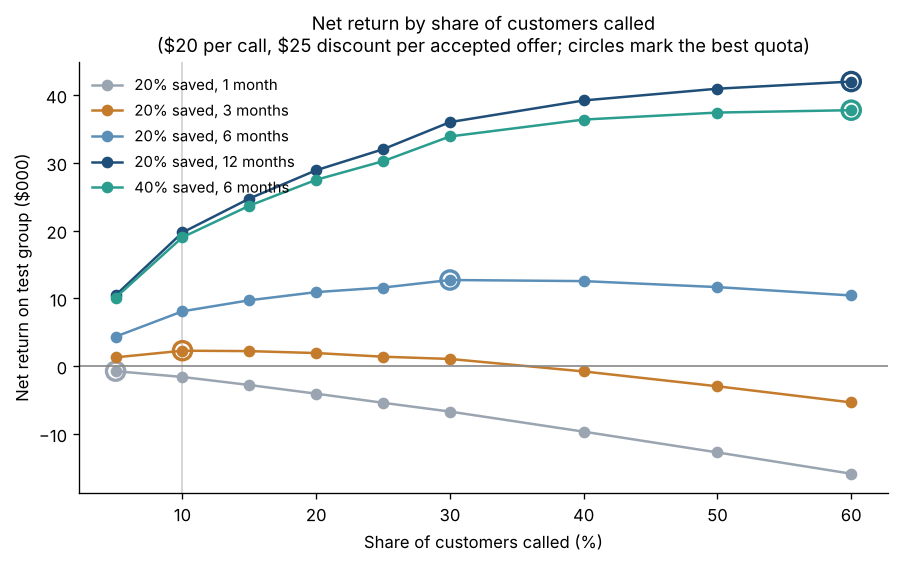

In [23]:
# Central case: $20 per call, $25 credit. Best quota and its net return by save rate and horizon.
central = scenarios[(scenarios["cost_per_call"] == 20) & (scenarios["credit"] == 25)]
best_grid = central.pivot(index="save_rate", columns="months", values="best_quota")
net_grid = central.pivot(index="save_rate", columns="months", values="net_at_best_quota")
ten_grid = central.pivot(index="save_rate", columns="months", values="net_at_10pct")
rule_grid = central.pivot(index="save_rate", columns="months", values="rule_share")
fmt_q = lambda v: f"{v:.0%}"
fmt_d = lambda v: f"${v:,.0f}"
for title, grid, f in [
    ("Profit-maximising quota (rows: save rate, columns: months a saved customer stays)", best_grid, fmt_q),
    ("Net return at that quota", net_grid, fmt_d),
    ("Net return at the 10% quota", ten_grid, fmt_d),
    ("Share of customers the profit rule would call", rule_grid, fmt_q),
]:
    print(title)
    display(grid.rename(index=lambda v: f"{v:.0%} saved").apply(lambda col: col.map(f)))

fig, ax = plt.subplots(figsize=(7.6, 4.8))
specs = [
    (0.20, 1, "#9aa5b1", "20% saved, 1 month"),
    (0.20, 3, "#c47b2b", "20% saved, 3 months"),
    (0.20, 6, "#5b8fb8", "20% saved, 6 months"),
    (0.20, 12, "#1f4e79", "20% saved, 12 months"),
    (0.40, 6, "#2a9d8f", "40% saved, 6 months"),
]
for s, m, color, label in specs:
    row = central[(central["save_rate"] == s) & (central["months"] == m)].iloc[0]
    ys = [row[f"net_q{int(q * 100)}"] / 1000 for q in QUOTAS_WIDE]
    ax.plot([q * 100 for q in QUOTAS_WIDE], ys, marker="o", color=color, label=label)
    ax.scatter([row["best_quota"] * 100], [row["net_at_best_quota"] / 1000], s=120, facecolor="none", edgecolor=color, lw=2)
ax.axhline(0, color="#888", lw=1)
ax.axvline(10, color="#d0d0d0", lw=1, zorder=0)
ax.set_xlabel("Share of customers called (%)")
ax.set_ylabel("Net return on test group ($000)")
ax.set_title("Net return by share of customers called\n" + r"(\$20 per call, \$25 discount per accepted offer; circles mark the best quota)", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()


In [24]:
# How much does each assumption move the answer? Hold the others at the central case
# (20% saved, 6 months, $20 per call, $25 credit) and vary one at a time.
base = dict(save_rate=0.20, months=6, cost_per_call=20, credit=25)
sens_rows = []
for field, values in [("save_rate", SAVE_RATES), ("months", MONTHS), ("cost_per_call", CALL_COSTS), ("credit", CREDITS)]:
    for v in values:
        cond = dict(base, **{field: v})
        r = scenarios[(scenarios["save_rate"] == cond["save_rate"]) & (scenarios["months"] == cond["months"])
                      & (scenarios["cost_per_call"] == cond["cost_per_call"]) & (scenarios["credit"] == cond["credit"])].iloc[0]
        sens_rows.append({"varied": field, "value": v, "net_at_10pct": r["net_at_10pct"],
                          "best_quota": r["best_quota"], "net_at_best_quota": r["net_at_best_quota"],
                          "rule_share": r["rule_share"], "rule_net": r["rule_net"]})
sens = pd.DataFrame(sens_rows)
display(sens.assign(
    net_at_10pct=sens["net_at_10pct"].map(fmt_d), best_quota=sens["best_quota"].map(fmt_q),
    net_at_best_quota=sens["net_at_best_quota"].map(fmt_d), rule_share=sens["rule_share"].map(fmt_q),
    rule_net=sens["rule_net"].map(fmt_d)))

c0 = scenarios[(scenarios["save_rate"] == 0.20) & (scenarios["months"] == 6) & (scenarios["cost_per_call"] == 20) & (scenarios["credit"] == 25)].iloc[0]
print(
    f"Central case: the 10% list returns ${c0['net_at_10pct']:,.0f}; the best quota is {c0['best_quota']:.0%} "
    f"returning ${c0['net_at_best_quota']:,.0f}; the expected-value rule calls {c0['rule_share']:.0%} of customers "
    f"and returns ${c0['rule_net']:,.0f} on the test group (about five times that across the whole base)."
)


,varied,value,net_at_10pct,best_quota,net_at_best_quota,rule_share,rule_net
0,save_rate,0.1,"$2,643",15%,"$2,756",24%,"$2,358"
1,save_rate,0.2,"$8,106",30%,"$12,724",37%,"$12,646"
2,save_rate,0.3,"$13,569",50%,"$24,555",43%,"$24,996"
3,save_rate,0.4,"$19,032",60%,"$37,783",49%,"$37,852"
4,months,1.0,"$-1,587",5%,$-731,0%,$0
5,months,3.0,"$2,290",10%,"$2,290",22%,"$1,841"
6,months,6.0,"$8,106",30%,"$12,724",37%,"$12,646"
7,months,12.0,"$19,737",60%,"$42,008",52%,"$41,078"
8,cost_per_call,10.0,"$9,516",60%,"$18,891",49%,"$18,926"
9,cost_per_call,20.0,"$8,106",30%,"$12,724",37%,"$12,646"


Central case: the 10% list returns $8,106; the best quota is 30% returning $12,724; the expected-value rule calls 37% of customers and returns $12,646 on the test group (about five times that across the whole base).


The quota scan answers the feedback directly. When saved customers stay only a month, the call cost and the discounts outweigh one month of bills, and no quota makes money: the best choice is to call no one. At three months the best quota is around 10% unless the save rate is high. Once a saved customer stays six months or more, calls far down the ranked list still pay, so the profit-maximising quota is well **above** 10% (30% in the central case of 20% saved, \$20 per call and a \$25 discount, and the top of the 60% range tried at twelve months). The 10% limit is then a staff-capacity constraint, not the profit-maximising choice, and the case for more retention capacity can be made in dollars.

The expected-value rule reaches similar answers without knowing outcomes, because it uses the model's probabilities, which section 7 found to be well calibrated. It is the rule to run on a live book once the save rate and offer take-up have been measured with a control group. Until then, every figure here is a scenario, not an estimate.


### 11c. Does the model choice change when it is judged on profit?

Model selection in section 6 used lost-bill coverage at a 10% quota. If profit is what matters, the fair question is whether any model earns more money, not just finds more lost bills. Each list is judged on three numbers in the central scenario (20% of contacted leavers saved, 6 months, \$20 per call, \$25 discount):

1. **Net at 10%**: realised net return when the top 10% of the list is called.
2. **Net at best quota**: the highest net return across quotas from 5% to 60%.
3. **Profit rule**: call everyone whose expected value, computed from *that model's own* predicted probability, is positive. This is the only number that also tests whether each model's probabilities are good enough to set the size of the list. The rules have no probability, so they cannot use it.

The test-group figures come with a paired bootstrap. The same comparison is repeated on the 20 training splits from section 6 (refit in each split, Nadeau-Bengio intervals), which is the like-for-like check of the selection rule. Amounts on the splits are per 1,000 customers so folds of different size can be compared.


In [25]:
S0, M0, C0, K0 = 0.20, 6, 20, 25
PROFIT_QUOTAS = QUOTAS_WIDE
model_probas = {
    "Logistic x bill": probas["logistic regression"],
    "Random forest x bill": probas["random forest"],
    "XGBoost x bill": probas["xgboost"],
    "Neural net x bill": probas["neural network"],
}
profit_lists = ["Logistic x bill", "Random forest x bill", "XGBoost x bill", "Neural net x bill",
                "Five-flag count x bill", "Contract-rate x bill", "Newest first", "Largest bill"]


def net_generic(yy, bb, chosen, s=S0, m=M0, c=C0, k=K0):
    yc, bc = yy[chosen], bb[chosen]
    return (yc * s * (m * bc - k)).sum() - ((1 - yc) * s * k).sum() - c * len(chosen)


def profit_summary(yy, bb, score, proba=None, s=S0, m=M0, c=C0, k=K0):
    order = np.argsort(-np.asarray(score, dtype=float), kind="mergesort")
    n = len(yy)
    nets = {q: net_generic(yy, bb, order[: max(1, int(round(n * q)))], s, m, c, k) for q in PROFIT_QUOTAS}
    best_q = max(nets, key=nets.get)
    out = {"net_at_10pct": nets[0.10], "best_quota": best_q, "net_at_best_quota": nets[best_q]}
    if proba is not None:
        ev = proba * s * (m * bb - k) - (1 - proba) * s * k - c
        chosen = np.where(ev > 0)[0]
        out["rule_share"] = len(chosen) / n
        out["rule_net"] = net_generic(yy, bb, chosen, s, m, c, k)
    else:
        out["rule_share"] = np.nan
        out["rule_net"] = np.nan
    return out


rows = []
for name in profit_lists:
    rows.append({"list": name, **profit_summary(y_holdout, bill, scores[name], model_probas.get(name))})
profit_test = pd.DataFrame(rows)

# Other horizons: net at best quota
for months in (3, 12):
    profit_test[f"best_net_{months}mo"] = [
        profit_summary(y_holdout, bill, scores[name], model_probas.get(name), m=months)["net_at_best_quota"]
        for name in profit_lists
    ]

# Paired bootstrap on the test group, same resampling scheme as section 7
rng_p = np.random.default_rng(RANDOM_STATE)
B_P = 2000
boot_net10 = {name: np.empty(B_P) for name in profit_lists}
boot_rule = {name: np.empty(B_P) for name in model_probas}
for b_i in range(B_P):
    ix = rng_p.integers(0, n_test, n_test)
    yy, bb = y_holdout[ix], bill[ix]
    for name in profit_lists:
        order = np.argsort(-np.asarray(scores[name], dtype=float)[ix], kind="mergesort")[: int(round(n_test * 0.10))]
        boot_net10[name][b_i] = net_generic(yy, bb, order)
    for name, pr in model_probas.items():
        p_ix = pr[ix]
        ev = p_ix * S0 * (M0 * bb - K0) - (1 - p_ix) * S0 * K0 - C0
        boot_rule[name][b_i] = net_generic(yy, bb, np.where(ev > 0)[0])


def ci_vs_logistic(draws, name):
    d = draws[name] - draws["Logistic x bill"]
    lo, hi = np.percentile(d, [2.5, 97.5])
    return f"{d.mean():+,.0f} ({lo:+,.0f} to {hi:+,.0f})"


profit_test["net10_diff_vs_logistic"] = [ci_vs_logistic(boot_net10, n) if n != "Logistic x bill" else "" for n in profit_lists]
profit_test["rule_diff_vs_logistic"] = [ci_vs_logistic(boot_rule, n) if n in model_probas and n != "Logistic x bill" else "" for n in profit_lists]

dollar_cols = ["net_at_10pct", "net_at_best_quota", "rule_net", "best_net_3mo", "best_net_12mo"]
view = profit_test.copy()
for col in dollar_cols:
    view[col] = profit_test[col].map(lambda v: "" if pd.isna(v) else f"${v:,.0f}")
view["best_quota"] = profit_test["best_quota"].map(lambda v: f"{v:.0%}")
view["rule_share"] = profit_test["rule_share"].map(lambda v: "" if pd.isna(v) else f"{v:.0%}")
print("Test group, central scenario (20% saved, 6 months, $20 per call, $25 credit). Bootstrap: 2,000 paired resamples.")
display(view[["list", "net_at_10pct", "net10_diff_vs_logistic", "best_quota", "net_at_best_quota",
              "rule_share", "rule_net", "rule_diff_vs_logistic", "best_net_3mo", "best_net_12mo"]])


Test group, central scenario (20% saved, 6 months, $20 per call, $25 credit). Bootstrap: 2,000 paired resamples.


,list,net_at_10pct,net10_diff_vs_logistic,best_quota,net_at_best_quota,rule_share,rule_net,rule_diff_vs_logistic,best_net_3mo,best_net_12mo
0,Logistic x bill,"$8,106",,30%,"$12,724",37%,"$12,646",,"$2,290","$42,008"
1,Random forest x bill,"$7,826","-416 (-1,219 to +391)",30%,"$12,657",40%,"$12,339","-308 (-1,081 to +531)","$2,239","$42,016"
2,XGBoost x bill,"$7,703","-536 (-1,382 to +274)",40%,"$12,872",37%,"$12,748","+118 (-726 to +1,000)","$2,309","$41,712"
3,Neural net x bill,"$7,311","-893 (-1,785 to -110)",40%,"$13,093",34%,"$12,612",-23 (-797 to +697),"$2,151","$41,801"
4,Five-flag count x bill,"$5,886","-2,091 (-3,126 to -1,046)",40%,"$12,180",,,,"$1,509","$40,370"
5,Contract-rate x bill,"$5,208","-3,089 (-4,384 to -1,805)",30%,"$11,334",,,,$975,"$40,142"
6,Newest first,"$2,143","-5,913 (-7,358 to -4,502)",50%,"$8,308",,,,$-373,"$36,825"
7,Largest bill,$469,"-7,479 (-9,195 to -5,824)",50%,"$7,938",,,,$-887,"$34,333"


In [26]:
# Same comparison on the 20 training splits used in section 6 (settings locked, refit in each split).
rep_profit = {name: {"net10": [], "best": [], "rule": []} for name in
              ["Logistic regression", "Random forest", "XGBoost", "Neural network", "Five-flag count x bill", "Contract-rate x bill"]}
for inner, outer in splits:
    outer_x = X_train.iloc[outer]
    bb = outer_x["MonthlyCharges"].to_numpy(dtype=float)
    yy = y_train.iloc[outer].to_numpy()
    per_k = 1000 / len(yy)
    for name, builder in name_to_builder.items():
        pr = builder().fit(X_train.iloc[inner], y_train.iloc[inner]).predict_proba(outer_x)[:, 1]
        res = profit_summary(yy, bb, pr * bb, pr)
        rep_profit[name]["net10"].append(res["net_at_10pct"] * per_k)
        rep_profit[name]["best"].append(res["net_at_best_quota"] * per_k)
        rep_profit[name]["rule"].append(res["rule_net"] * per_k)
    rates = (pd.DataFrame({"Contract": X_train.iloc[inner]["Contract"].to_numpy(), "churn": y_train.iloc[inner].to_numpy()})
             .groupby("Contract")["churn"].mean())
    for name, score in [("Contract-rate x bill", outer_x["Contract"].map(rates).to_numpy() * bb),
                        ("Five-flag count x bill", np.asarray(flag_count(outer_x), dtype=float) * bb)]:
        res = profit_summary(yy, bb, score)
        rep_profit[name]["net10"].append(res["net_at_10pct"] * per_k)
        rep_profit[name]["best"].append(res["net_at_best_quota"] * per_k)
        rep_profit[name]["rule"].append(np.nan)

rows = []
for name, d in rep_profit.items():
    row = {"method": name}
    for key, label in [("net10", "net_at_10pct"), ("best", "net_at_best_quota"), ("rule", "profit_rule")]:
        v = np.array(d[key], dtype=float)
        if np.isnan(v).all():
            row[label] = ""
            row[label + "_diff"] = ""
            continue
        ref = np.array(rep_profit["Logistic regression"][key], dtype=float)
        diff = v - ref
        half = t_crit * diff.std(ddof=1) * np.sqrt(1 / J + test_to_train)
        row[label] = f"${v.mean():,.0f}"
        row[label + "_diff"] = "" if name == "Logistic regression" else f"{diff.mean():+,.0f} ({diff.mean() - half:+,.0f} to {diff.mean() + half:+,.0f}); better in {(diff > 0).mean():.0%}"
    rows.append(row)
rep_profit_table = pd.DataFrame(rows)
print("20 training splits, net return per 1,000 customers, central scenario. Difference vs logistic regression with Nadeau-Bengio 95% interval and share of splits where the method earns more.")
display(rep_profit_table)


20 training splits, net return per 1,000 customers, central scenario. Difference vs logistic regression with Nadeau-Bengio 95% interval and share of splits where the method earns more.


,method,net_at_10pct,net_at_10pct_diff,net_at_best_quota,net_at_best_quota_diff,profit_rule,profit_rule_diff
0,Logistic regression,"$5,408",,"$10,090",,"$10,134",
1,Random forest,"$5,412",+4 (-345 to +353); better in 45%,"$10,229",+139 (-111 to +390); better in 65%,"$10,234",+100 (-205 to +405); better in 60%
2,XGBoost,"$5,579",+171 (-171 to +513); better in 75%,"$10,313",+223 (-94 to +540); better in 85%,"$10,423",+289 (-20 to +598); better in 80%
3,Neural network,"$5,326",-81 (-334 to +171); better in 40%,"$10,183",+93 (-168 to +353); better in 65%,"$10,162",+29 (-212 to +269); better in 65%
4,Five-flag count x bill,"$4,361","-1,046 (-1,509 to -584); better in 0%","$9,487",-603 (-940 to -265); better in 0%,,
5,Contract-rate x bill,"$3,954","-1,454 (-2,005 to -904); better in 0%","$9,376","-714 (-1,108 to -321); better in 0%",,


Judged on money instead of coverage, **the decision does not change**, but the picture is a little more nuanced.

- **At a 10% quota, profit follows coverage.** Logistic regression earns the most on the test group (\$8,106), and on the training splits the three challengers are within a few hundred dollars per 1,000 customers with intervals spanning zero.
- **Once the list may grow, the models converge.** At the best quota the four models are within \$450 of each other on the test group (\$12,657 to \$13,093). On the training splits XGBoost is slightly ahead (+\$223 per 1,000 customers at the best quota, +\$289 under the profit rule) and earns more in 80-85% of splits, but its intervals still include zero. For scale, the 2-point coverage margin is worth about \$470 per 1,000 customers in this scenario (2% of roughly \$19,500 of lost monthly bills per 1,000 customers × 20% saved × 6 months), so XGBoost's profit edge is about 60% of the bar it would need to clear. It is a small, consistent edge worth re-testing on a later month, not a reason to give up the readable model now.
- **The simple rules stay clearly behind, but the gap narrows as the list grows.** The five-flag rule is about \$2,100 behind on the test group at 10% and about \$540 behind at its best quota; on the training splits its gap falls from \$1,046 to \$603 per 1,000 customers, still clear of zero. With a larger quota most leavers are reached by any sensible ranking, so the model's advantage is greatest when calls are scarce.
- **The profit rule works with every model.** Each model's own probabilities set a list of 34-40% of customers that earns about the same as the best fixed quota, so the calibrated logistic probabilities are good enough to size the list as well as order it.


## 12. What this score cannot do, and what would come next

The four methods estimate the chance that a customer **looks like past leavers**. The company actually wants the chance that a customer **stays because of the offer**.

A customer with a 90% chance of leaving who will leave no matter what is a poor use of the slot. A customer with a 60% chance who would stay if given security support may be the better call. This file has no past offers, no treatment and control groups, and no record of who responded, so that uplift cannot be trained here.

The next stage, if the company starts running keep-offers with a holdout, is to rank by expected extra revenue from intervening, not by leave risk alone.


Two further limits of the file itself. First, it is one snapshot of who had already left, so tenure and some service fields describe customers *at* departure. A live customer base will not look the same, which is why a later-month holdout matters. Second, the call list is nearly a single segment (month-to-month fibre, mostly electronic check), so the models are mostly recovering that rule and ordering it by bill and tenure. That is why the five-flag rule is the right benchmark and why the model's edge over it, about six points at a 10% quota, is the number to quote.

## 13. Recommendation

If the company can contact only about 1 in 10 customers, rank by predicted chance of leaving times the monthly bill. Under the pre-set rule that is logistic regression, because no more complex method added 2 points on the training folds. No complex model beats logistic regression by a margin the data can resolve (the repeated-fold intervals for the forest, XGBoost and the network all span zero, and on the test group the network is, if anything, slightly behind), so choose on readability and operating cost, not on a leaderboard. The model's real edge is over the manager rules: about 6-9 points over contract-rate × bill and about 4-7 points over the five-flag rule at a 10% quota (4.4 in repeated cross-validation, 6.8 on the single test split), with the interval for each shown in the tables above.

Use the ranking as a human call queue, not as an automatic discount.

Do not give every contact the same offer. New high-value customers (month-to-month, a year or less, bill at least $70) are offered a one-year contract that includes online security and tech support. Longer-tenure fibre customers who have neither extra are offered those extras, with a one-time credit, rather than a new-customer contract. Anyone on the list who already has one of those extras is reviewed individually. Stable one-year and two-year customers stay off a quota this tight. All of these offers are hypotheses to test with a control group.

At larger quotas the gap to the simple rules narrows. At a 30% quota the contract-rate spreadsheet is about 4 points behind logistic regression and the five-flag rule about 3 points behind. Both gaps are still larger than the 2-point margin the notebook demands of a complex model, so the model stays ahead there too, by less.

The programme value depends on two numbers this file cannot supply: the share of contacted leavers who are saved, and how many months they stay. The tables in section 11 show the combinations that break even.

Before using the list on a live book, repeat the comparison on a recent billing extract and hold out a later month. This file is a teaching sample with no dates, so the test group is not later customers, and tenure describes customers at departure. There is no keep-offer history, so the save rate is an assumption, not an estimate.


In [27]:
hit_rate = float(model_row["share_of_calls_who_left"])
print(
    f"Call list: {chosen_name}, ranked by predicted chance of leaving times the monthly bill."
)
print(
    f"At a 10% quota the list reaches {model_row['share_of_lost_bills']:.1%} of lost monthly bills "
    f"(${lost_on_list:,.0f}) using {contacts} contacts, of whom {hit_rate:.1%} had left in this extract."
)
print(
    "The random forest, XGBoost and neural network replace logistic regression only if they add at least "
    "2 percentage points of lost-bill coverage on the training folds. That rule, not a leaderboard "
    "of ROC AUC, decides which model the company should use, and no complex model beats logistic regression by a margin the data can resolve."
)
print(
    "On the call list, new high-value customers are offered a one-year contract with security and "
    "tech support. Longer-tenure unprotected fibre customers are offered those extras instead. "
    "Stable customers are not called."
)


Call list: logistic regression, ranked by predicted chance of leaving times the monthly bill.
At a 10% quota the list reaches 35.4% of lost monthly bills ($9,692) using 141 contacts, of whom 74.5% had left in this extract.
The random forest, XGBoost and neural network replace logistic regression only if they add at least 2 percentage points of lost-bill coverage on the training folds. That rule, not a leaderboard of ROC AUC, decides which model the company should use, and no complex model beats logistic regression by a margin the data can resolve.
On the call list, new high-value customers are offered a one-year contract with security and tech support. Longer-tenure unprotected fibre customers are offered those extras instead. Stable customers are not called.
